<a href="https://colab.research.google.com/github/Andoniadou-Lab/PCP_sc_spatial/blob/main/London_team/Fig1B_1C_1D_3A_PCP_sc_integration_and_dotplots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook describes the processing and integration process for the scRNA-seq analysis.

The notebook produces plots for Figure 1B/C/D and Figure 3A

# Install packages

In [ ]:
!pip install scikit-misc
!pip install igraph
!pip install decoupler==1.8.0
!pip install scvi-tools -U
!pip install git+https://github.com/Novartis/scAR.git
!pip install leidenalg
!pip install anndata
!pip install scanpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 182.4/182.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 48.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 28.4 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.5/731.5 kB 16.7 MB/s eta 0:00:

# Mount drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import scanpy as sc

# Reading in kallisto folders from my Google Drive. (If anyone else mounted their drive, it won't have these folders)

In [ ]:
folders = [
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES21644390B/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES21644790B/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES231739100B/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES232243100B/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES232245100B/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES232911100B/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013270/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013271/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013272/",
    "/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013273/"]

# Loading back each of the anndata objects into a list

In [ ]:
#/content/drive/MyDrive/pituitary_tumor_atlas/source_table/pituitary_tumor_atlas.xlsx
import pandas as pd
import numpy as np

df = pd.read_excel("/content/drive/MyDrive/pituitary_tumor_atlas/source_table/pituitary_tumor_atlas.xlsx")
df

,Internal_ID,GEO,SRA_ID,Name,Normal,DOI,Author,Tumor_pta,Conditions,Age,...,sc_sn_atac,pseudoaligned,passed_qc,filtering_junk,median_cellassign_prob,most_recent_workflow,n_cells,Notes:,passed_qc_tcc,tcc_pseudobulked
0,pta_sc_1,GSM8848663,SRX28013261,tumor tissue of adamantinomatous craniopharyng...,0.0,https://doi.org/10.1016/j.isci.2024.111068,Matsuda et al. (2024),ACP,ACP,72.0,...,sc,1.0,1.0,1.0,NaN,NaN,NaN,have to figure out what the invasiveness means...,NaN,NaN
1,pta_sc_2,GSM8848664,SRX28013262,tumor tissue of adamantinomatous craniopharyng...,0.0,https://doi.org/10.1016/j.isci.2024.111068,Matsuda et al. (2024),ACP,ACP,75.0,...,sc,1.0,NaN,1.0,1.000000,v_0.01,2603.0,NaN,NaN,NaN
2,pta_sc_3,GSM8848665,SRX28013263,tumor tissue of adamantinomatous craniopharyng...,0.0,https://doi.org/10.1016/j.isci.2024.111068,Matsuda et al. (2024),ACP,ACP,59.0,...,sc,1.0,NaN,1.0,1.000000,v_0.01,2854.0,NaN,NaN,NaN
3,pta_sc_4,GSM8848666,SRX28013260,tumor tissue of adamantinomatous craniopharyng...,0.0,https://doi.org/10.1016/j.isci.2024.111068,Matsuda et al. (2024),ACP,ACP,25.0,...,sc,1.0,NaN,1.0,1.000000,v_0.01,3737.0,NaN,NaN,NaN
4,pta_sc_5,GSM8848667,SRX28013264,tumor tissue of adamantinomatous craniopharyng...,0.0,https://doi.org/10.1016/j.isci.2024.111068,Matsuda et al. (2024),ACP,ACP,25.0,...,sc,1.0,NaN,1.0,1.000000,v_0.01,4850.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119,NaN,NaN,SRX21219339,Gon#2,NaN,doi.org/10.1093/neuonc/noaf241,Ilie et al. (2025),NaN,NaN,66.0,...,sc,1.0,NaN,1.0,1.000000,v_0.01,2669.0,NaN,NaN,NaN
120,NaN,NaN,SRX21219340,Gon#3,NaN,doi.org/10.1093/neuonc/noaf241,Ilie et al. (2025),NaN,NaN,57.0,...,sc,1.0,NaN,1.0,0.993441,v_0.01,4051.0,NaN,NaN,NaN
121,NaN,NaN,SRX21219341,Gon#4,NaN,doi.org/10.1093/neuonc/noaf241,Ilie et al. (2025),NaN,NaN,78.0,...,sc,1.0,NaN,1.0,0.998125,v_0.01,4372.0,NaN,NaN,NaN
122,NaN,NaN,SRX21219342,Gon#5,NaN,doi.org/10.1093/neuonc/noaf241,Ilie et al. (2025),NaN,NaN,78.0,...,sc,1.0,NaN,1.0,1.000000,v_0.01,3485.0,NaN,NaN,NaN


In [ ]:
folders

['/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES21644390B/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES21644790B/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES231739100B/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES232243100B/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES232245100B/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/OES232911100B/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013270/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013271/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013272/',
 '/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/SRX28013273/']

In [ ]:
#make a table of gene occurrances
import anndata
adatas= []
for i in folders:
  sample_ID=i.split('/')[-2]
  print(sample_ID)

  adatas.append(anndata.read(f"/content/drive/MyDrive/pituitary_tumor_atlas/processed/nac/{sample_ID}/analysis/adata_assigned.h5ad"))


OES21644390B


/usr/local/lib/python3.11/dist-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


OES21644790B


/usr/local/lib/python3.11/dist-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


OES231739100B


...

/usr/local/lib/python3.11/dist-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


SRX28013272


/usr/local/lib/python3.11/dist-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


SRX28013273


/usr/local/lib/python3.11/dist-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


# Adding a dataset ID to each cell and then merging the objects

In [ ]:
#merge and add dataset name to obs
for adata,folder in zip(adatas,folders):
  sample_ID=folder.split('/')[-1]
  adata.obs["dataset"] = sample_ID
adata_final = adatas[0].concatenate(adatas[1:])

<ipython-input-7-368721dd62ac>:5: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_final = adatas[0].concatenate(adatas[1:])


In [ ]:
adata_final

AnnData object with n_obs × n_vars = 66577 × 27578
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'dataset', 'batch'
    var: '0', 'feature_types', 'mt', 'ribo', 'malat', 'n_cells_by_counts-0', 'mean_counts-0', 'log1p_mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_total_counts-0', 'n_cells_by_counts-1', 'mean_counts-1', 'log1p_mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_total_counts-1', 'n_cells_by_counts-2', 'mean_counts-2', 'log1p_mean_counts-2', 'pct_dropout_by_counts-2', 'total_counts-2', 'log1p_total_counts-2', 'n_cells_by_counts-3', 'mean_counts-3', 'log1p_mean_counts-3'

# Saving object to drive

In [ ]:
#write out for seurat
adata_final.write(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/adata_merged_0331.h5ad")

# Performing some preliminary analysis on the unintegrated object

In [ ]:
import anndata
adata_final = anndata.read(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/adata_merged_0331.h5ad")

/usr/local/lib/python3.11/dist-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [ ]:
import scanpy as sc
adata_before = adata_final.copy()
sc.pp.filter_genes(adata_before, min_cells=30)
sc.pp.normalize_total(adata_before, target_sum=1e4)
sc.pp.log1p(adata_before)
sc.pp.highly_variable_genes(adata_before, flavor="seurat", n_top_genes=2000)
sc.pp.scale(adata_before, max_value=10)
sc.tl.pca(adata_before, svd_solver='arpack')
sc.pp.neighbors(adata_before, n_neighbors=10, n_pcs=30)
sc.tl.umap(adata_before)

# To illustrate the integration process, here is the UMAP *before* integration

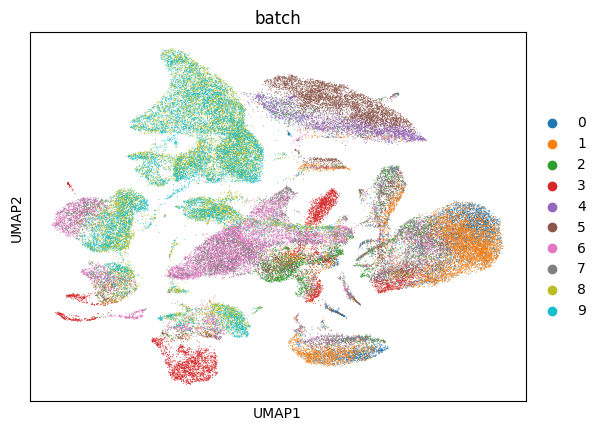

In [ ]:
#plot umap
sc.pl.umap(adata_before, color=["batch"])

# Choose top 20000 most variable genes. These are basically the only ones we are interested in.

In [ ]:
!pip install numba --upgrade

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 45.9 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.4
    Uninstalling numpy-2.2.4:
      Successfully uninstalled numpy-2.2.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
captum 0.8.0 requires numpy<2.0, but you have numpy 2.1.3 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.2.3 which is incompatible.
distributed-ucxx-cu12 0.42.0 requires numba<0.61.0a0,>=0.59.1, but you have numba 0.61.0 which is incompatible.
rapids-dask-dependency 25.2.0 requires dask==2024.12.1, but you have dask 2024.7.1 which is incompatible.
rapids-dask-dependency 25.2.0 requires dask-expr==1.1.21, but you have dask-expr 1.1.9 which is incompatible.
rapids-dask-depen

In [ ]:
import scanpy as sc
adata_final.raw = adata_final # keep full dimension
adata_final.layers['counts']=adata_final.X.copy()
sc.pp.highly_variable_genes(
    adata_final,
    flavor="seurat_v3",
    n_top_genes=20000,
    layer="counts",
    batch_key="batch",
    subset=True,
)

# Training the model, saving the model, and getting the latent dimensions and "normalised" counts.

In [ ]:
import scvi
scvi.model.SCVI.setup_anndata(adata_final, layer="counts", batch_key="batch")

/usr/local/lib/python3.11/dist-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/usr/local/lib/python3.11/dist-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [ ]:
vae = scvi.model.SCVI(adata_final, n_layers=2, n_latent=30, gene_likelihood="nb")

In [ ]:
vae.train(max_epochs=200)

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
/usr/local/lib/python3.11/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training:   0%|          | 0/200 [00:00<?, ?it/s]

In [ ]:
#save this vae
dir_path = "/content/drive/MyDrive/pituitary_tumor_atlas/vae_0331"
vae.save(dir_path, overwrite=True)

In [ ]:
#load vae - when running this make sure you've also ran the highly variable genes step above
vae = scvi.model.SCVI.load(dir_path, adata_final)

In [ ]:
 #plot convergence
import matplotlib.pyplot as plt
plt.plot(vae.history["reconstruction_loss_train"], label="train")

In [ ]:
adata_final.obsm["X_scVI"] = vae.get_latent_representation()

# Running Leiden clustering, and showing UMAP (I wouldn't really trust UMAPs for anything complicated, but it is fine to use it to judge whether integration worked at all.)

In [ ]:
sc.pp.neighbors(adata_final, use_rep="X_scVI")
sc.tl.leiden(adata_final, resolution=1.2, key_added="leiden_scVI", random_state=42)

In [ ]:
sc.tl.umap(adata_final, min_dist=0.2,spread=1)

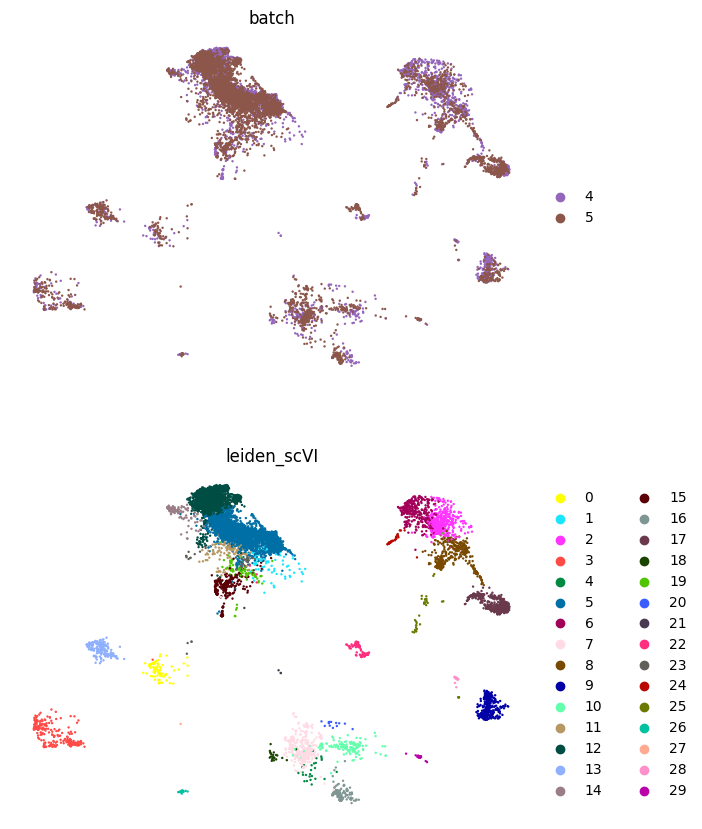

In [ ]:
sc.pl.umap(
    adata_final[adata_final.obs.batch.isin(["4","5"])],
    color=["batch", "leiden_scVI"],
    frameon=False,
    ncols=1,
)

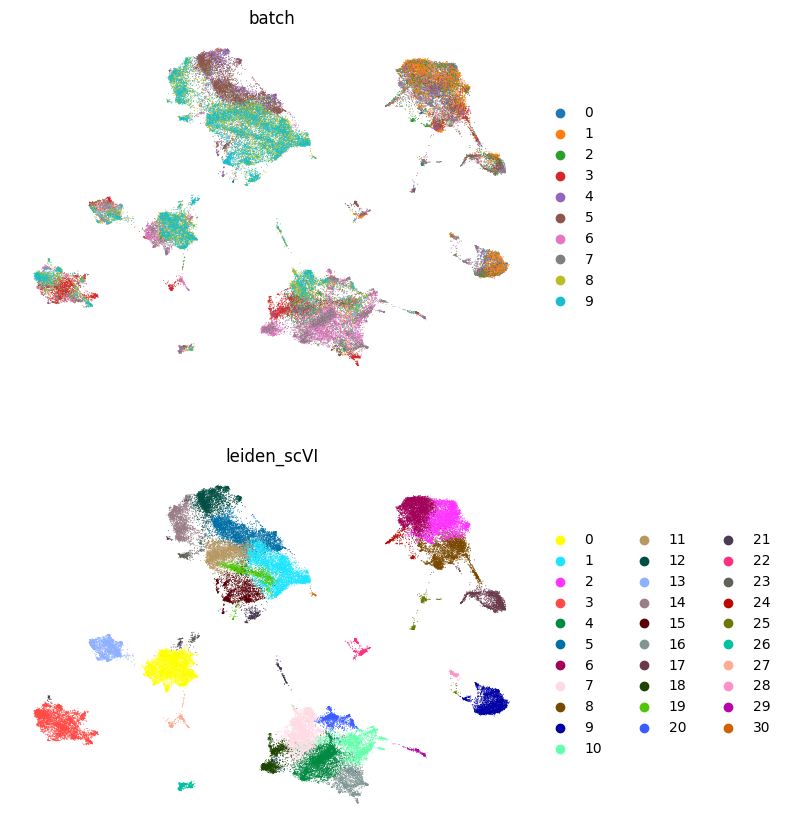

In [ ]:
sc.pl.umap(
    adata_final,
    color=["batch", "leiden_scVI"],
    frameon=False,
    ncols=1,
)

# Printing cluster abundances

In [ ]:
#print out frequency of each cluster
adata_final.obs.leiden_scVI.value_counts()

,count
leiden_scVI,
0,5029
1,4743
2,4400
3,4284
4,4090
5,4059
6,4048
7,3958
8,3215


In [ ]:
adata_final.layers["SCVI_normalised"] = vae.get_normalized_expression(transform_batch="4")

In [ ]:
#norm and log1p
sc.pp.normalize_total(adata_final, target_sum=1e4)
sc.pp.log1p(adata_final)

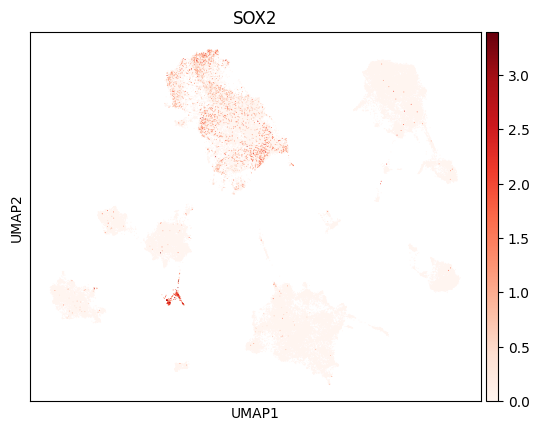

In [ ]:
sc.pl.umap(
    adata_final,
    color="SOX2",
    use_raw=False,
    cmap=plt.cm.Reds)

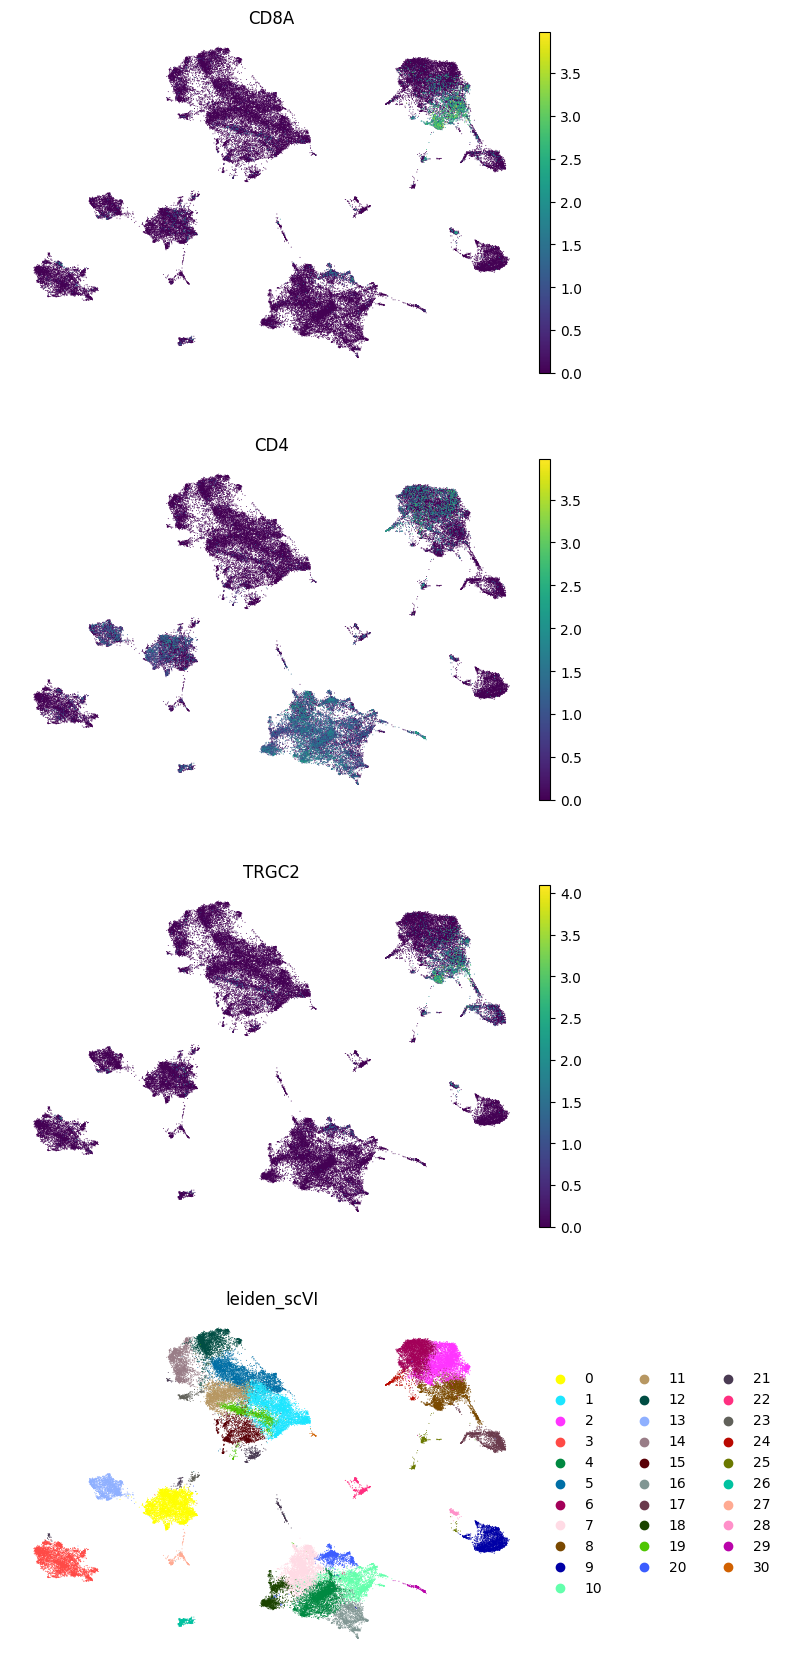

In [ ]:
sc.pl.umap(
    adata_final,
    color=["CD8A","CD4","TRGC2","leiden_scVI"],
    frameon=False,
    ncols=1,
    use_raw=False,
    sort_order=True
)

# DE analysis

In [ ]:
#get markers
df = vae.differential_expression(groupby="leiden_scVI",batch_correction=True)
df.head()

DE...:   0%|          | 0/31 [00:00<?, ?it/s]

# Printing marker genes following differential expression analysis

In [ ]:
markers = {}
for c in adata_final.obs.leiden_scVI.cat.categories:
    cell_df = df.loc[df.group1 == c]
    markers[c] = cell_df.index.tolist()[:50]
markers

{'0': ['SFRP4',
  'LTBP2',
  'CLDN11',
  'FBLN2',
  'SFRP2',
  'BICC1',
  'APOD',
  'ITGBL1',
  'CCDC80',
  'LAMA2',
  'RARRES2',
  'ISLR',
  'TWIST1',
  'CTSK',
  'LUM',
  'THBS2',
  'C1S',
  'PCOLCE',
  'C7',
  'DCN',
  'MGP',
  'CTHRC1',
  'COL1A1',
  'COL6A3',
  'COL1A2',
  'MXRA8',
  'IGFBP6',
  'AEBP1',
  'COL13A1',
  'COL3A1',
  'LRRC17',
  'RCN3',
  'LINC01088',
  'FMOD',
  'C1R',
  'COL5A1',
  'PRELP',
  'DPYSL3',
  'ABCA6',
  'FN1',
  'CLEC11A',
  'PRICKLE1',
  'NTRK3',
  'NR2F1',
  'DIO2',
  'NBL1',
  'GFPT2',
  'NR2F1-AS1',
  'ABCA9',
  'PDGFRA'],
 '1': ['LCN2',
  'KRT7',
  'SLC6A14',
  'ELF3',
  'MYH14',
  'CLDN4',
  'CXCL17',
  'CEACAM1',
  'RDH10',
  'PITX1',
  'PDP1',
  'GDF15',
  'ST6GALNAC1',
  'RDH10-AS1',
  'SCNN1A',
  'MAP3K13',
  'FAM3C',
  'PRSS22',
  'TSPAN1',
  'RASEF',
  'PLS1',
  'GPRC5A',
  'MUC1',
  'CLDN7',
  'DSG2',
  'HEBP2',
  'CDKN2A',
  'MDK',
  'RHOV',
  'SLPI',
  'LIPH',
  'WFDC2',
  'TMPRSS4',
  'CA12',
  'MBOAT2',
  'HS3ST1',
  'MME',
  'TMEM45B',

\# Published human markers from Zhang et al. 2022

§
Gonadotropes
FSHB, LHB, GNRHR, CGA, ESR1, TCERG1L, TGFBR3L, PCSK2

Corticotropes
POMC, CRHR1, GAL, OPCML, RAB3B, TBX19, CDH7, KCNH7

Somatotropes
GH1, GHRHR, KCNMB2, ROBO2, SGCD

Thyrotropes
DCC, DIO2, PID1, ANQ4, CDH12, ADARB2

Lactotropes
PRL, ALK, ANGPT1, ROBO1

Stem cells (sc)
RBPMS, SOX9, LGR4, SOX2, IQCJ-SCHIP1, NTNG1, EBF1, BNC2, GRHL2, ADGRA3

Endothelial
PLVAP, EMCN, FLT1, ESAM, ADGRL4, STC1

T cells
CD3D, CD3G, CD2, CD7, LCK, THEMIS, ITK, CD96, CD69, CD247

Pericytes
MGP, DCN, APOD, S1PR3, TAGLN, PDGFRA, BGN

Immune cells
PTPRC, CD53

Macrophages
CD163, C1QA, C1QB, C1QC, MS4A7, HLA-DRA, HLA-DRB1, HLA-DPB1, CSF1R, CD86

Pituicytes
COL25A1, FAT3, HMCN1, DLGAP1, ADGRL3, LAMA2, NKAIN2

Epithelial
PIGR, KRT7, KRT17, MUC4

B Cells
BANK1, FCRL1, MS4A1, CD79A


Interm. lobe sc
PAX7

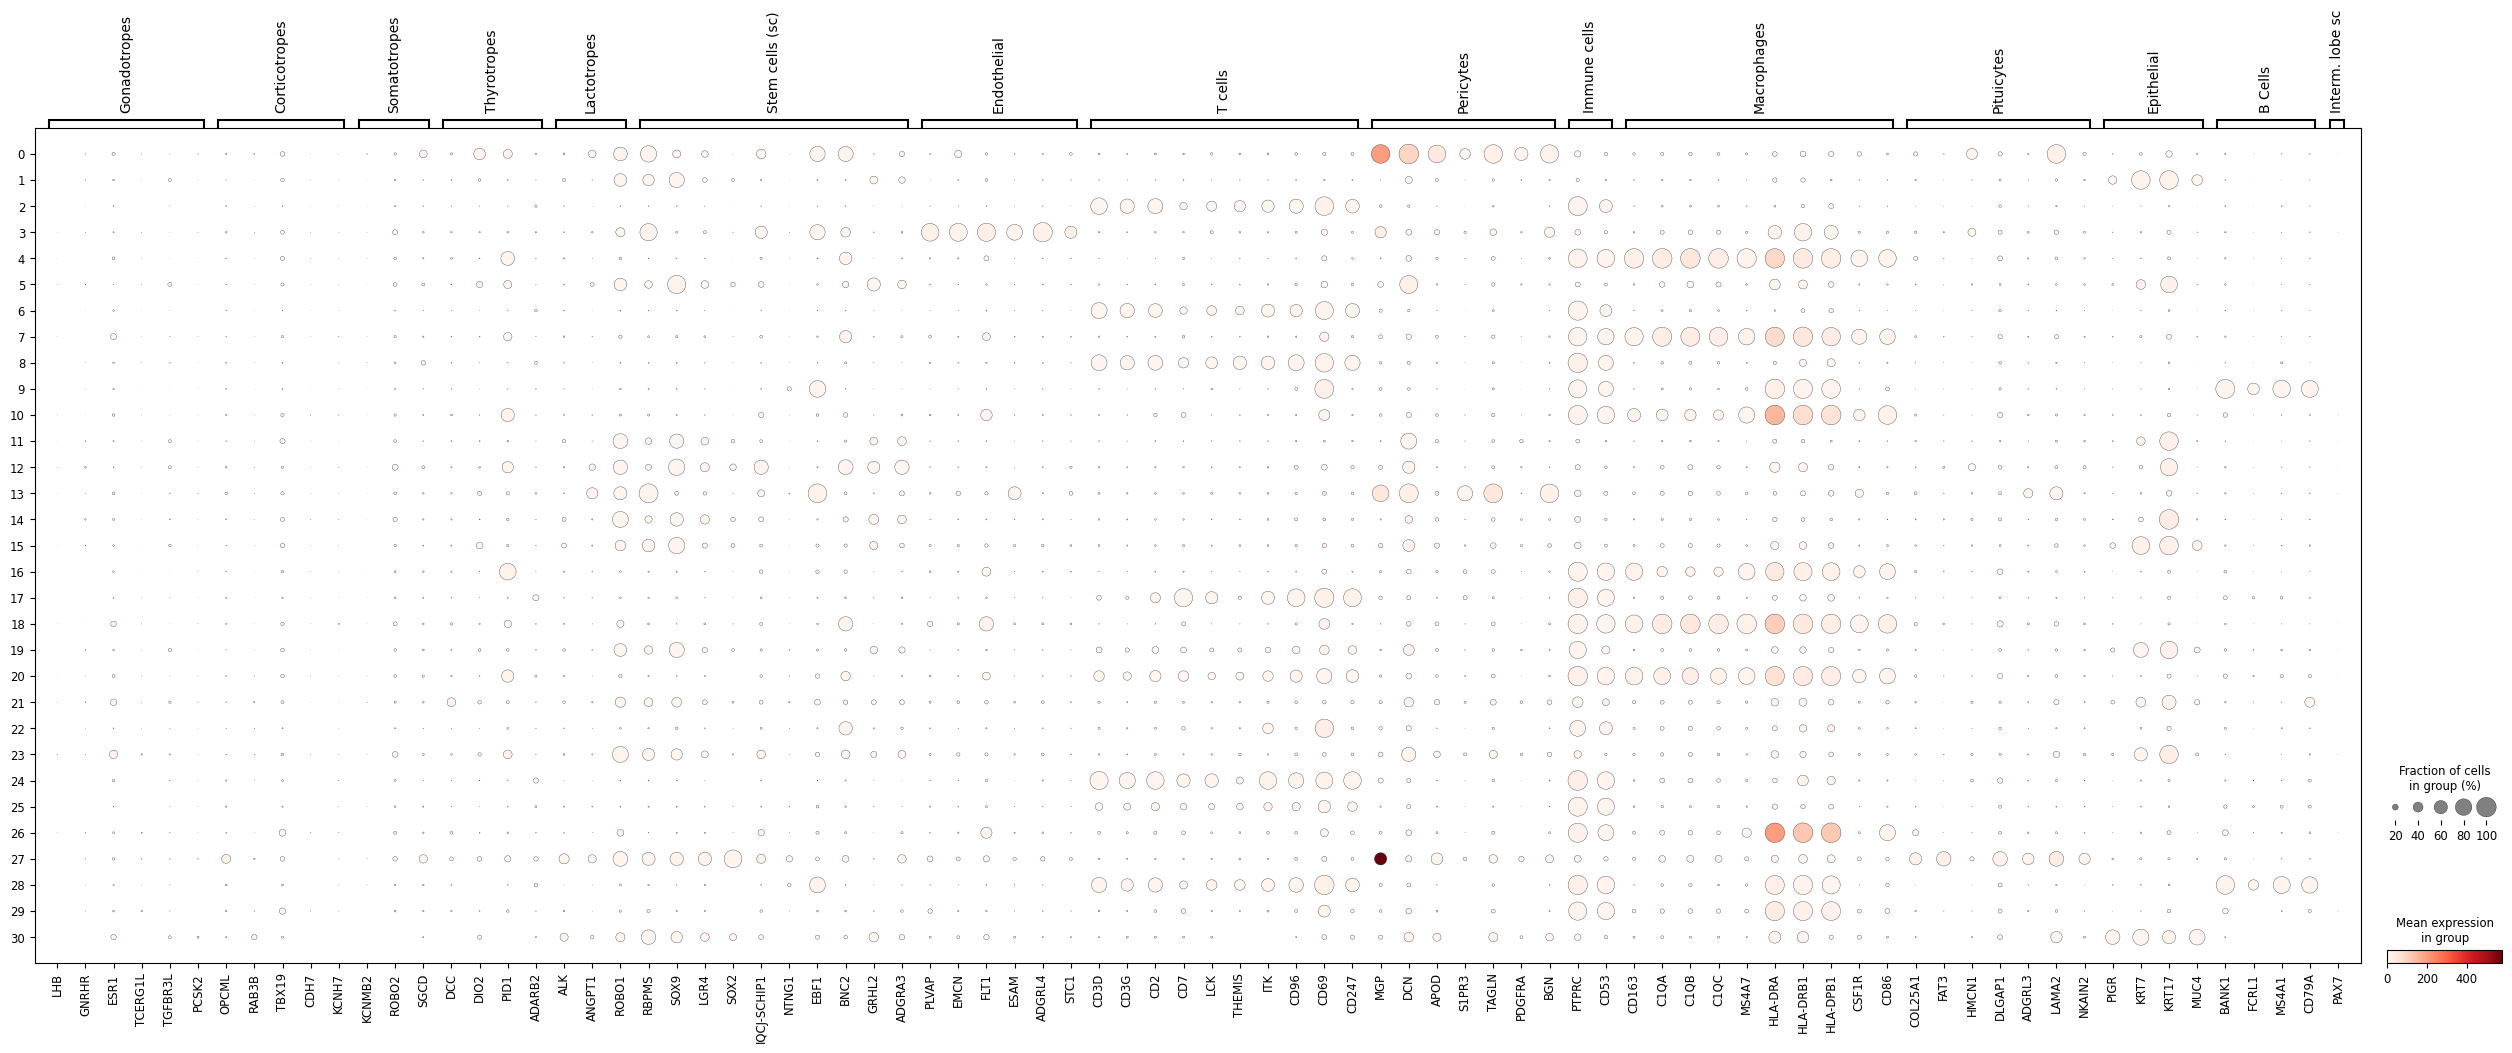

In [ ]:
markers = {
    "Gonadotropes": ["FSHB", "LHB", "GNRHR", "CGA", "ESR1", "TCERG1L", "TGFBR3L", "PCSK2"],
    "Corticotropes": ["POMC", "CRHR1", "GAL", "OPCML", "RAB3B", "TBX19", "CDH7", "KCNH7"],
    "Somatotropes": ["GH1", "GHRHR", "KCNMB2", "ROBO2", "SGCD"],
    "Thyrotropes": ["DCC", "DIO2", "PID1", "ANQ4", "CDH12", "ADARB2"],
    "Lactotropes": ["PRL", "ALK", "ANGPT1", "ROBO1"],
    "Stem cells (sc)": ["RBPMS", "SOX9", "LGR4", "SOX2", "IQCJ-SCHIP1", "NTNG1", "EBF1", "BNC2", "GRHL2", "ADGRA3"],
    "Endothelial": ["PLVAP", "EMCN", "FLT1", "ESAM", "ADGRL4", "STC1"],
    "T cells": ["CD3D", "CD3G", "CD2", "CD7", "LCK", "THEMIS", "ITK", "CD96", "CD69", "CD247"],
    "Pericytes": ["MGP", "DCN", "APOD", "S1PR3", "TAGLN", "PDGFRA", "BGN"],
    "Immune cells": ["PTPRC", "CD53"],
    "Macrophages": ["CD163", "C1QA", "C1QB", "C1QC", "MS4A7", "HLA-DRA", "HLA-DRB1", "HLA-DPB1", "CSF1R", "CD86"],
    "Pituicytes": ["COL25A1", "FAT3", "HMCN1", "DLGAP1", "ADGRL3", "LAMA2", "NKAIN2"],
    "Epithelial": ["PIGR", "KRT7", "KRT17", "MUC4"],
    "B Cells": ["BANK1", "FCRL1", "MS4A1", "CD79A"],
    "Interm. lobe sc": ["PAX7"]
}

#remove values from each list that are not in var
markers = {k: [x for x in v if x in adata_final.var_names] for k, v in markers.items()}

sc.pl.dotplot(adata_final, markers, groupby="leiden_scVI", dendrogram=False
          )

# Showing some more markers, partially taken from the Chinese manuscript

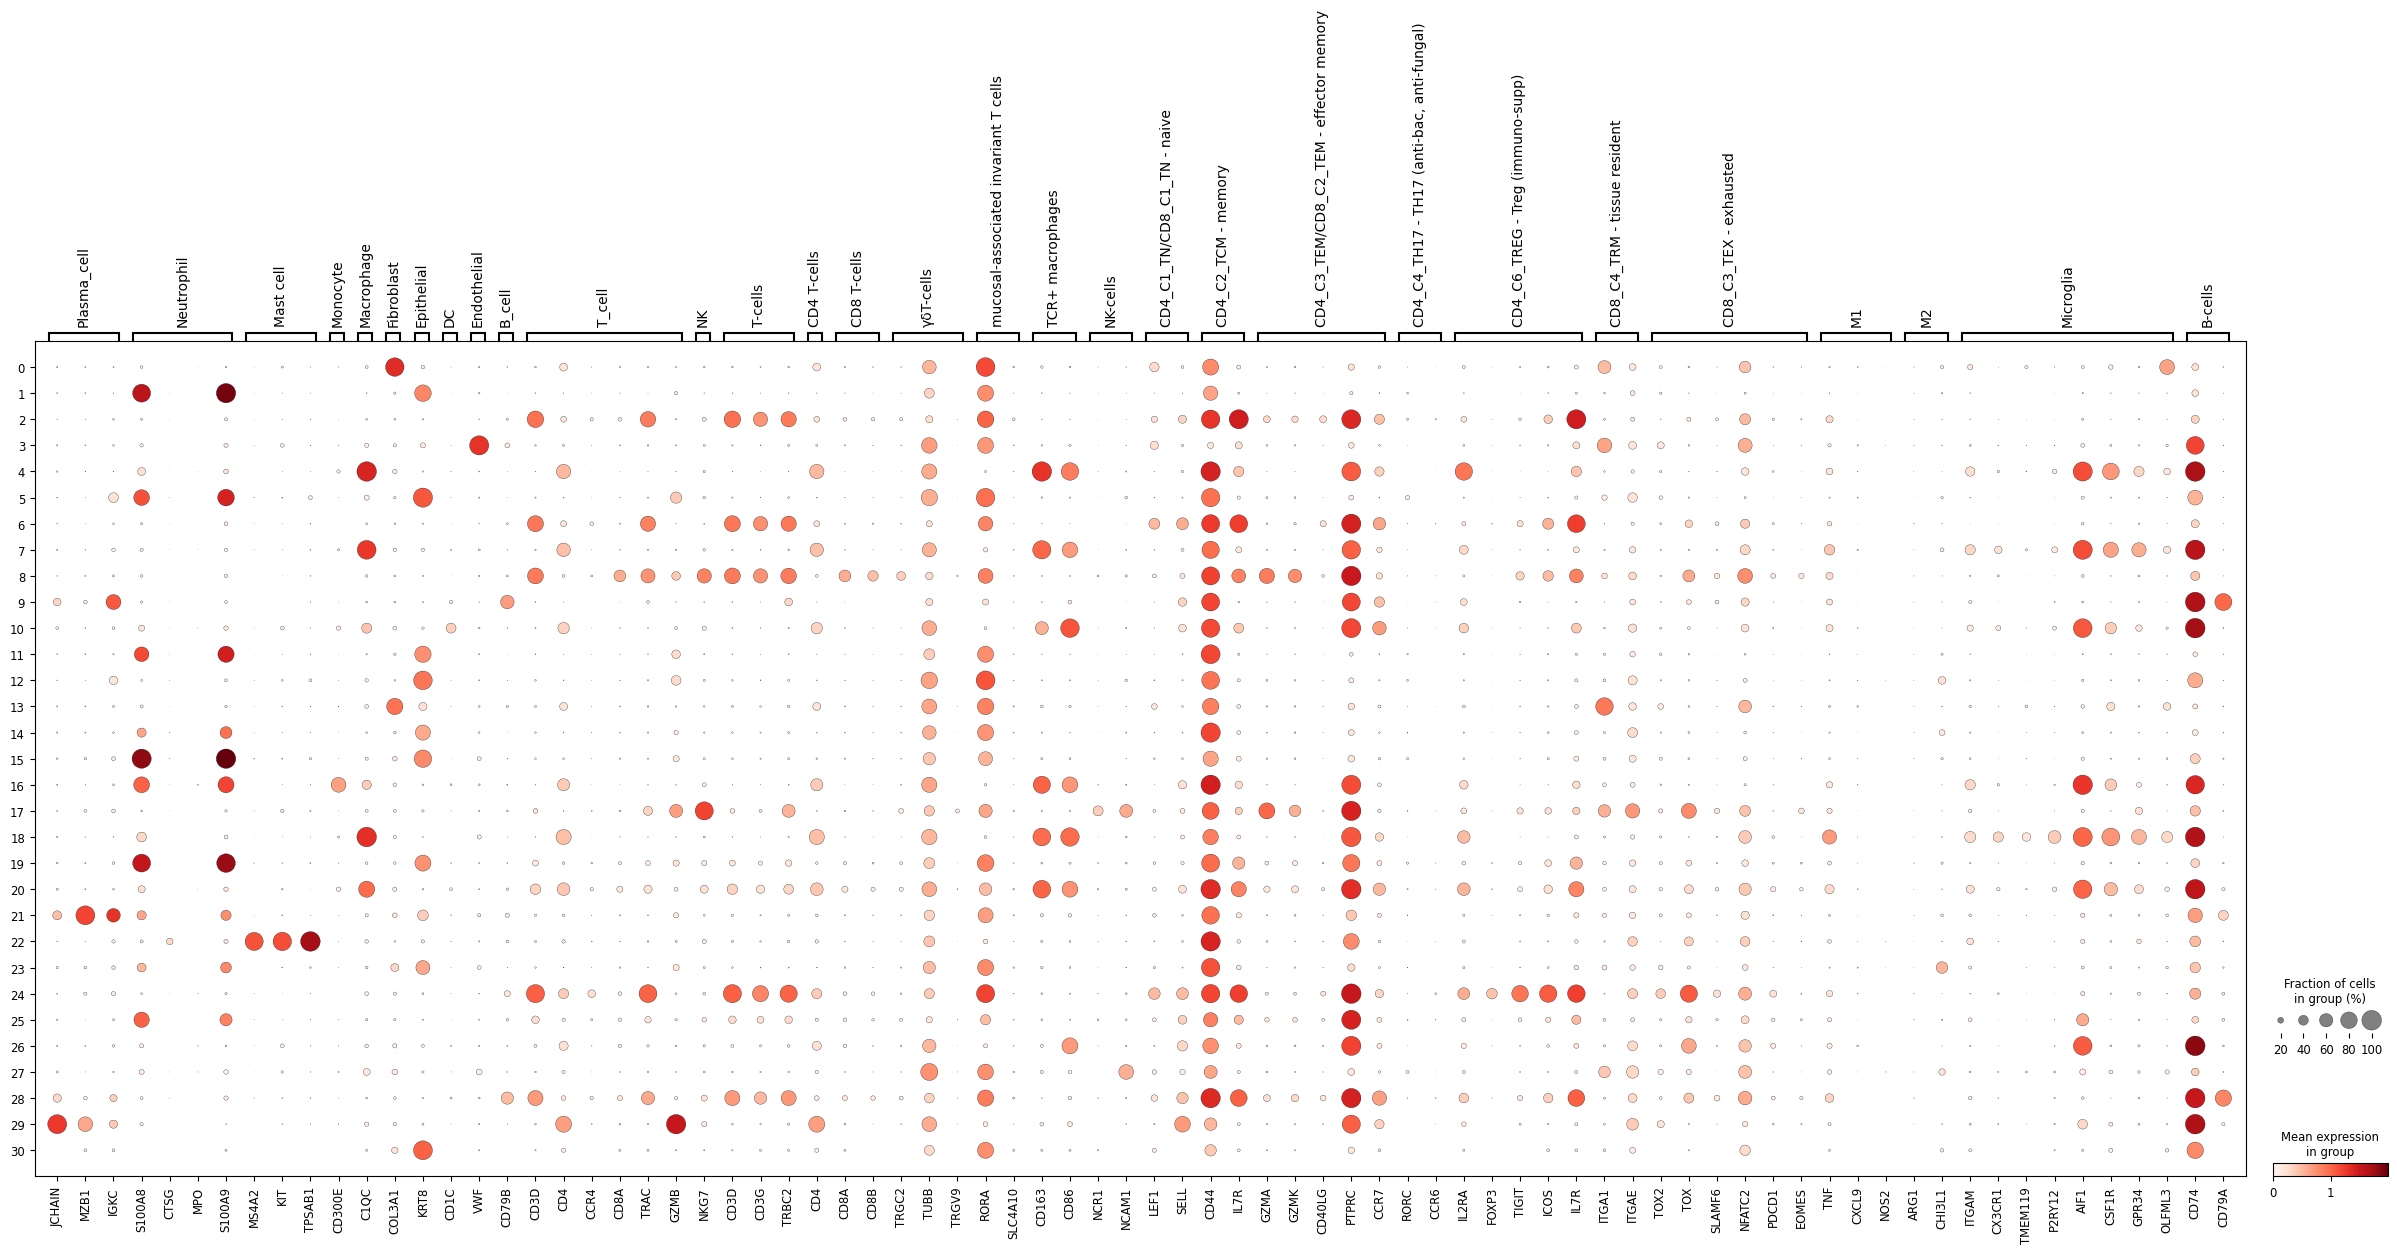

In [ ]:
markers = {
    "Plasma_cell": ["JCHAIN", "MZB1", "IGKC"],
    "Neutrophil": ["CSFJR","S100A8","CTSG", "MPO","S100A9"],
    "Mast cell" : ["MS4A2","KIT", "TPSAB1"],
    "Monocyte": ["CD300E"],
    "Macrophage": ["C1QC"],
    "Fibroblast": ["COL3A1"],
    "Epithelial": ["KRT8"],
    "DC": ["CD1C"],
    "Endothelial": ["VWF"],
    "B_cell": ["CD79B"],
    "T_cell": ["CD3D", "CD4", "CCR4", "CD8A", "TRAC", "GZMB"],
    "NK": ["NKG7"],
    "T-cells": ["CD3D", "CD3G", "TRBC2"],
    "CD4 T-cells": ["CD4"],
    "CD8 T-cells": ["CD8A", "CD8B"],
    "γδT-cells": ["TRGC2", "TRG-AS", "TUBB", "TRGV9"],
    "mucosal-associated invariant T cells": ["RORA", "SLC4A10"],
    "TCR+ macrophages": ["CD163", "CD86"],
    "NK-cells": ["NCR1", "NCAM1"],
    "CD4_C1_TN/CD8_C1_TN - naive": ["TCF7", "LEF1", "SELL"],
    "CD4_C2_TCM - memory": ["CD44", "IL7R"],
    "CD4_C3_TEM/CD8_C2_TEM - effector memory": ["GZMA", "GZMK", "CD40LG","PTPRC", "CCR7"],
    "CD4_C4_TH17 - TH17 (anti-bac, anti-fungal)": ["RORC", "CCR6"],
    "CD4_C6_TREG - Treg (immuno-supp)": ["IL2RA", "FOXP3","CD152","TIGIT","ICOS","IL7R"],
    "CD8_C4_TRM - tissue resident": ["ITGA1", "ITGAE"],
    "CD8_C3_TEX - exhausted": ["TOX2", "TOX", "SLAMF6", "NFATC2","PDCD1","EOMES","CD57"],
    "M1": ["TNF", "CXCL9", "NOS2"],
    "M2": ["ARG1", "CHI3L1", "RETNLB"],
    "Microglia": [
        "ITGAM", "CX3CR1", "TMEM119", "P2RY12", "AIF1", "CSF1R",
        "FCRLS", "SIGLECH", "GPR34", "OLFML3"
    ],
    "B-cells": ["CD74", "CD79A"]
}


#remove values from each list that are not in var
markers = {k: [x for x in v if x in adata_final.var_names] for k, v in markers.items()}

sc.pl.dotplot(adata_final, markers, groupby="leiden_scVI", dendrogram=False,use_raw=False,log=True
          )

/usr/local/lib/python3.11/dist-packages/scanpy/tools/_utils.py:40: UserWarning: You’re trying to run this on 20000 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(


categories: 0, 1, 2, etc.
var_group_labels: CD8_Cytotoxic, CD4_Th17, CD4_Th1, etc.


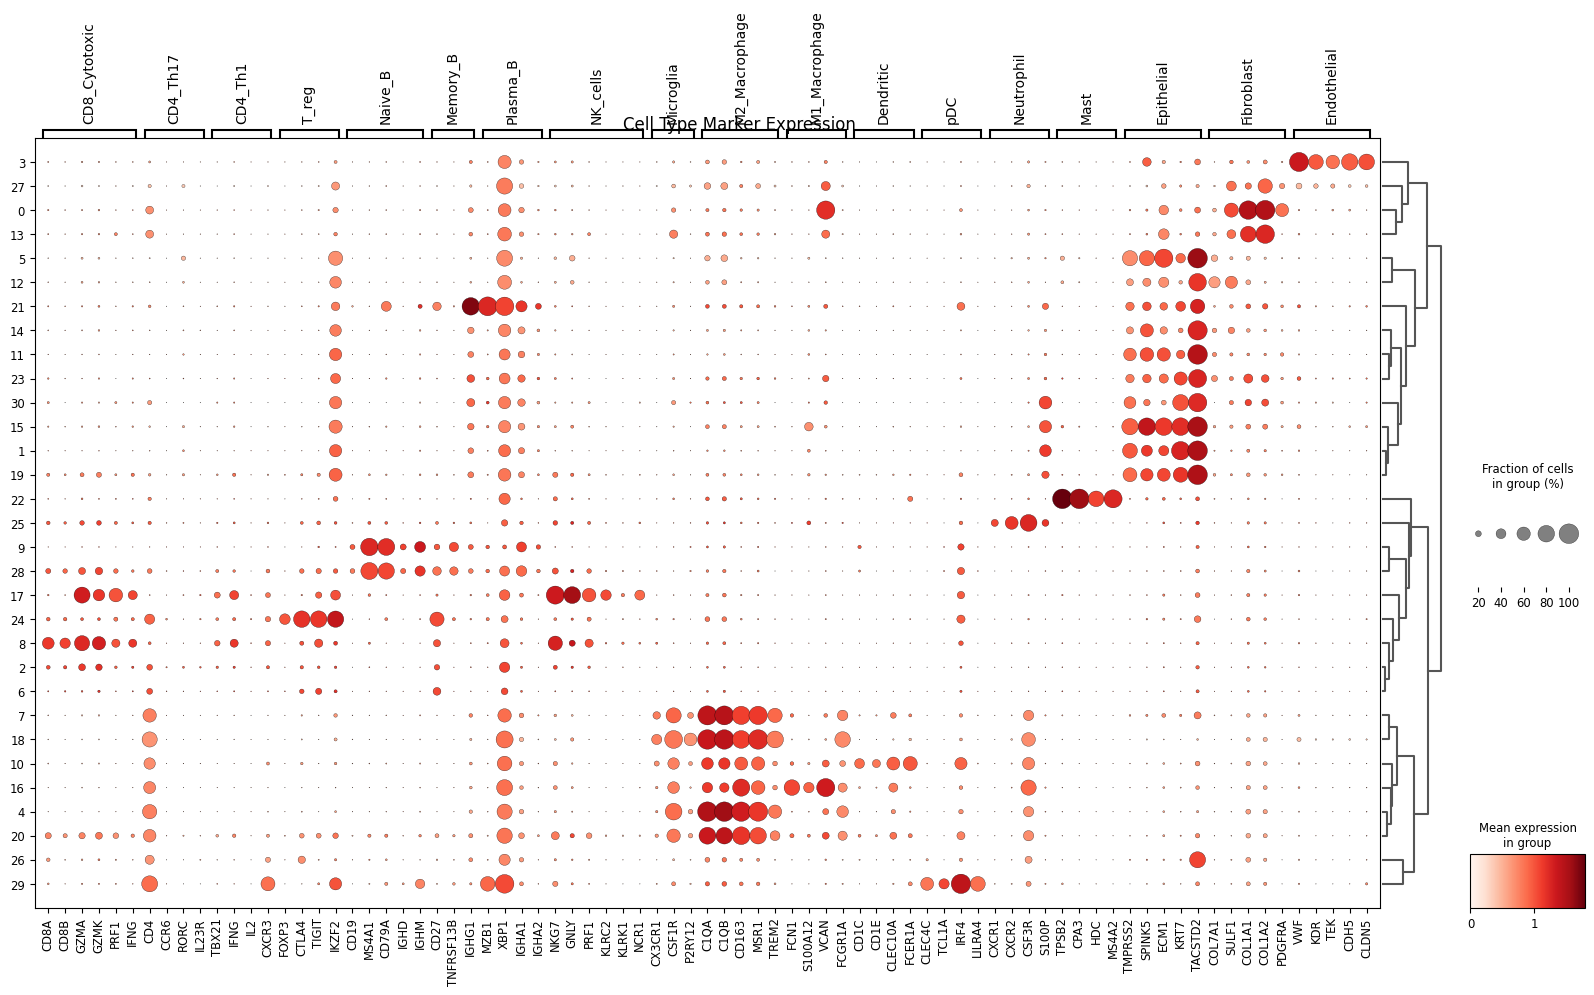

<Figure size 640x480 with 0 Axes>

In [ ]:
# Define markers dictionary with curated markers for each cell type
markers = {
    # T cell subtypes
    'CD8_Cytotoxic': ['CD8A', 'CD8B', 'GZMA', 'GZMK', 'PRF1', 'IFNG'],
    'CD4_Th17': ["CD4",'IL17A', 'CCR6', 'RORC', 'IL23R', 'IL21'],
    'CD4_Th1': ['TBX21', 'IFNG', 'IL2', 'CXCR3'],
    'T_reg': ['FOXP3', 'CTLA4', 'TIGIT', 'IKZF2'],

    # B cell subtypes
    'Naive_B': ['CD19', 'MS4A1', 'CD79A', 'IGHD', 'IGHM'],
    'Memory_B': ['CD27', 'TNFRSF13B', 'IGHG1'],
    'Plasma_B': ['MZB1', 'XBP1', 'IGHA1', 'IGHA2'],

    # Other immune cells
    'NK_cells': ['NKG7', 'GNLY', 'PRF1', 'KLRC2', 'KLRK1', 'NCR1'],
    'Microglia': ["CX3CR1", "CSF1R", "P2RY12"],
    'M2_Macrophage': ['C1QA', 'C1QB', 'CD163', 'MSR1', 'TREM2'],
    'M1_Macrophage': ['FCN1', 'S100A12', 'VCAN', 'FCGR1A'],
    'Dendritic': ['CD1C', 'CD1E', 'CLEC10A', 'FCER1A'],
    'pDC': ['CLEC4C', 'TCL1A', 'IRF4', 'LILRA4'],
    'Neutrophil': ['CXCR1', 'CXCR2', 'CSF3R', 'S100P'],
    'Mast': ['TPSB2', 'CPA3', 'HDC', 'MS4A2'],

    # Structural cells
    'Epithelial': ['TMPRSS2', 'SPINK5', 'ECM1', 'KRT7', 'TACSTD2'],
    'Fibroblast': ['COL7A1', 'SULF1', 'COL1A1', 'COL1A2', 'PDGFRA'],
    'Endothelial': ['VWF', 'KDR', 'TEK', 'CDH5', 'CLDN5']
}
# Remove values from each list that are not in var
markers = {k: [x for x in v if x in adata_final.var_names] for k, v in markers.items()}

# Create the dotplot
sc.pl.dotplot(adata_final,
              markers,
              groupby="leiden_scVI",
              figsize=(20, 10),
              dendrogram=True,
              use_raw=False,
              log=True,
              title='Cell Type Marker Expression',
              smallest_dot=0.2,
              mean_only_expressed=True)

plt.tight_layout()

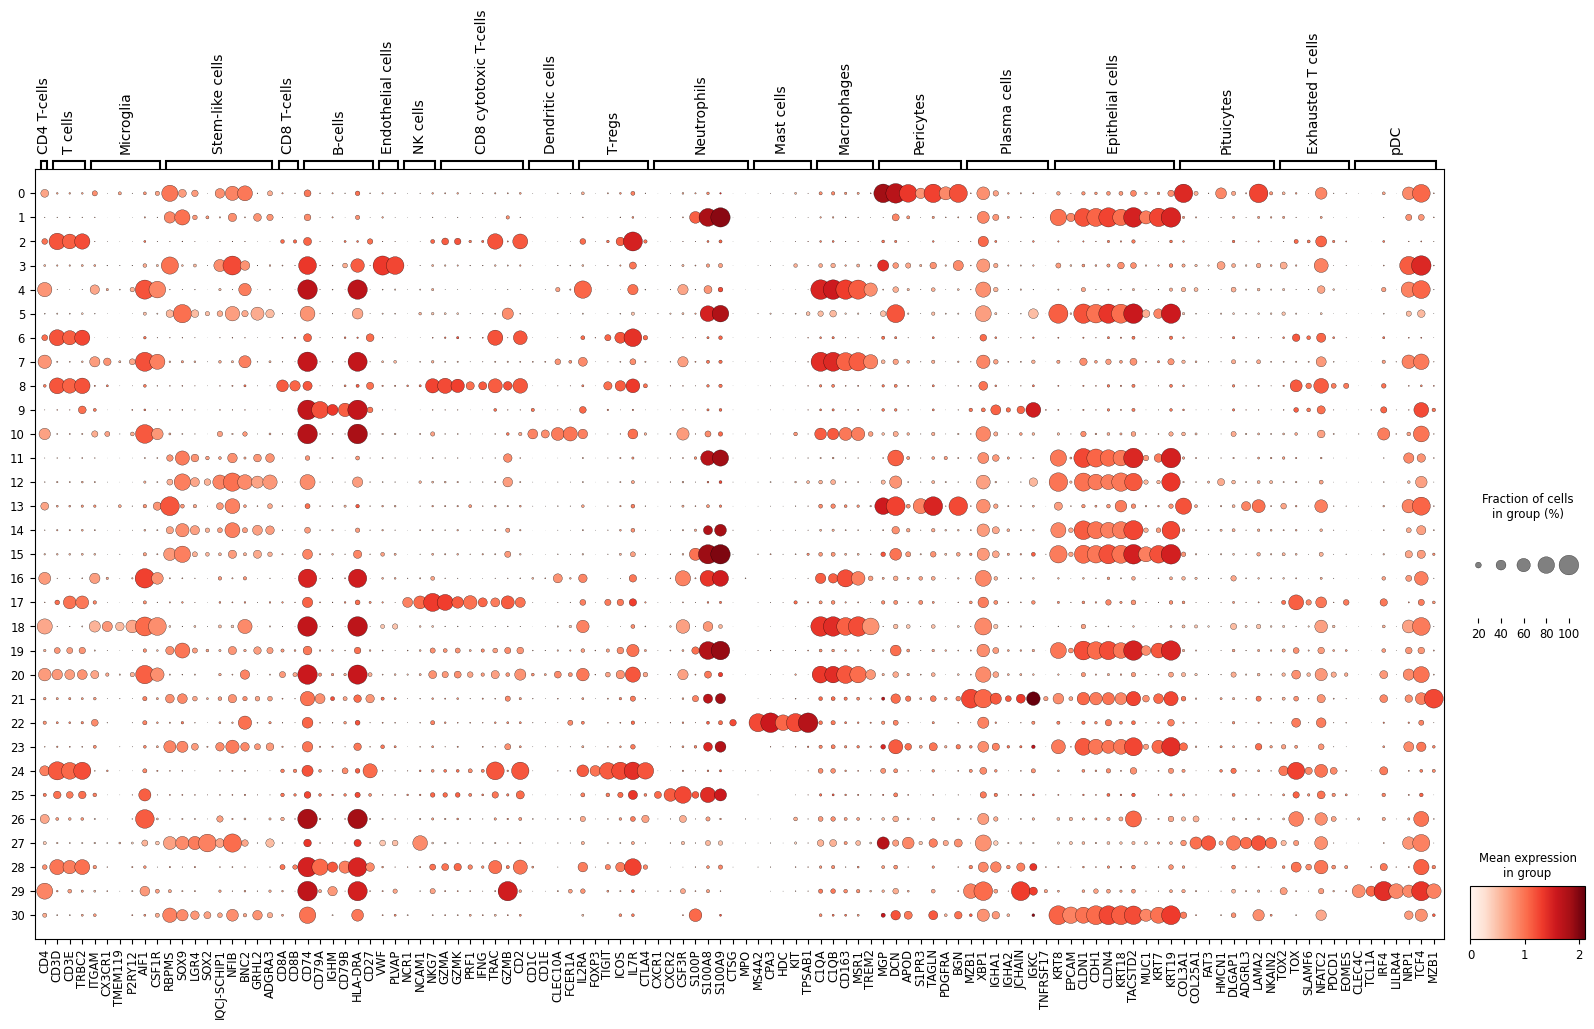

<Figure size 640x480 with 0 Axes>

In [ ]:
# Define markers dictionary with curated markers for each cell type
markers = {
    "CD4 T-cells" : ["CD4"],
    "T cells": ["CD3D", "CD3E", "TRBC2"],
    "Microglia" : ["ITGAM", "CX3CR1", "TMEM119", "P2RY12", "AIF1", "CSF1R"],
    "Stem-like cells": ["RBPMS", "SOX9", "LGR4", "SOX2", "IQCJ-SCHIP1", "NFIB", "BNC2", "GRHL2", "ADGRA3"],
    "CD8 T-cells": ["CD8A", "CD8B"],
    "B-cells": ["CD74", "CD79A", "IGHM","CD79B","HLA-DRA","CD27"],
    "Endothelial cells": ["VWF", "PLVAP"],
    "NK cells": ["NCR1", "NCAM1", "NKG7"],
    "CD8 cytotoxic T-cells": ["GZMA", "GZMK", "PRF1", "IFNG","TRAC","GZMB","CD2"],
    "Dendritic cells": ["CD1C", "CD1E", "CLEC10A", "FCER1A"],
    "T-regs": ["IL2RA", "FOXP3","CD152","TIGIT","ICOS","IL7R","CTLA4"],
    "Neutrophils": ["CXCR1", "CXCR2", "CSF3R", "S100P","CSFJR","S100A8", "S100A9", "CTSG","MPO"],
    "Mast cells": ["MS4A2", "CPA3", "HDC","KIT", "TPSAB1"],
    "Macrophages": ["C1QA", "C1QB", "CD163", "MSR1", "TREM2"],
    "Pericytes": ["MGP", "DCN", "APOD", "S1PR3", "TAGLN", "PDGFRA", "BGN"],
    "Plasma cells": ["MZB1", "XBP1", "IGHA1", "IGHA2","JCHAIN","IGKC","TNFRSF17"],
    "Epithelial cells": ["KRT8", "EPCAM","CLDN1", "CDH1","CLDN4","KRT18","TACSTD2","ZO1","MUC1","KRT7","KRT19"],
    "Pituicytes": ["COL3A1", "COL25A1", "FAT3", "HMCN1", "DLGAP1", "ADGRL3", "LAMA2", "NKAIN2"],
    "Exhausted T cells": ["TOX2", "TOX", "SLAMF6", "NFATC2","PDCD1","EOMES","CD57"],
    "pDC": ["CLEC4C", "TCL1A", "IRF4", "LILRA4","NRP1","TCF4","MZB1"]
}
# Remove values from each list that are not in var
markers = {k: [x for x in v if x in adata_final.var_names] for k, v in markers.items()}

# Create the dotplot
sc.pl.dotplot(adata_final,
              markers,
              groupby="leiden_scVI",
              figsize=(20, 10),
              use_raw=False,
              log=True,
              mean_only_expressed=True)

plt.tight_layout()

# Naming the clusters

In [ ]:
#based on all the above, we can construct a Leiden assignment - cell type dictionary
cell_type_dict = {
    "0": "Mesenchymal cells",
    "1": "Epithelial cells",
    "2": "CD4 T-cells",
    "3": "Endothelial cells",
    "4": "M2 Macrophages",
    "5": "Stem-like cells",
    "6": "CD4 T-cells",
    "7": "M2 Macrophages",
    "8": "CD8 cytotoxic T-cells",
    "9": "Naive B-cells",
    "10": "Dendritic cells",
    "11": "Stem-like cells",
    "12": "Stem-like cells",
    "13": "Pericytes",
    "14": "Stem-like cells",
    "15": "Epithelial cells",
    "16": "M1 Macrophages",
    "17": "CD8 cytotoxic T-cells",
    "18": "M2 Macrophages",
    "19": "Epithelial cells",
    "20": "M2 Macrophages",
    "21": "Plasma cells",
    "22": "Mast cells",
    "23": "Stem-like cells",
    "24": "CD4 T-regs",
    "25": "Neutrophils",
    "26": "M2 Macrophages",
    "27": "Pituicytes",
    "28": "Naive B-cells",
    "29": "pDC",
    "30": "Epithelial cells"
}

adata_final.obs["broad_cluster"] = adata_final.obs["leiden_scVI"].map(cell_type_dict)

In [ ]:
cell_type_dict = {
    "0": "Mesenchymal cells",
    "1": "Epithelial cells 1",
    "2": "CD4 T-cells 1",
    "3": "Endothelial cells",
    "4": "M2 Macrophages 1",
    "5": "Stem-like cells 1",
    "6": "CD4 T-cells 2",
    "7": "M2 Macrophages 2",
    "8": "CD8 cytotoxic T-cells 1",
    "9": "Naive B-cells 1",
    "10": "Dendritic cells",
    "11": "Stem-like cells 2",
    "12": "Stem-like cells 3",
    "13": "Pericytes",
    "14": "Stem-like cells 4",
    "15": "Epithelial cells 2",
    "16": "M1 Macrophages",
    "17": "CD8 cytotoxic T-cells 2",
    "18": "M2 Macrophages 3",
    "19": "Epithelial cells 3",
    "20": "M2 Macrophages 4",
    "21": "Plasma cells",
    "22": "Mast cells",
    "23": "Stem-like cells 5",
    "24": "CD4 T-regs",
    "25": "Neutrophils",
    "26": "M2 Macrophages 5",
    "27": "Pituicytes",
    "28": "Naive B-cells 2",
    "29": "pDC",
    "30": "Epithelial cells 4"
}

cell_type_dict = {str(k): v for k, v in cell_type_dict.items()}
adata_final.obs["Specific_cluster"] = adata_final.obs["leiden_scVI"].map(cell_type_dict)


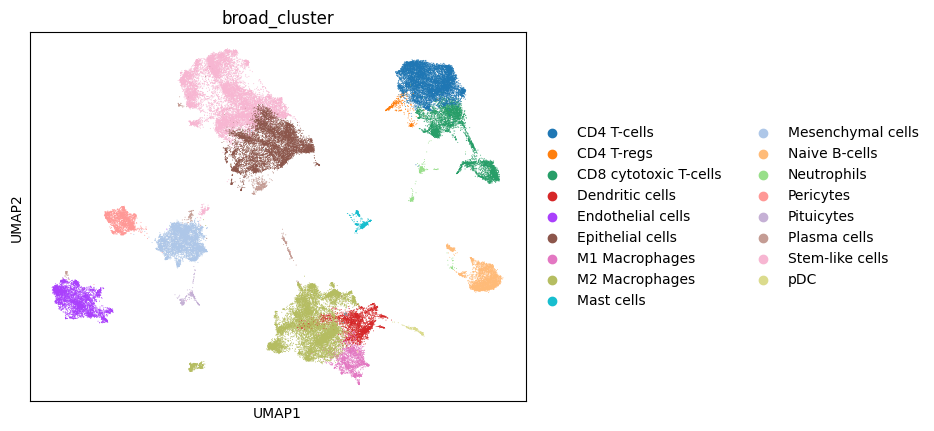

In [ ]:
#make umap with broad labels
import scanpy as sc
sc.pl.umap(adata_final, color=["broad_cluster"])

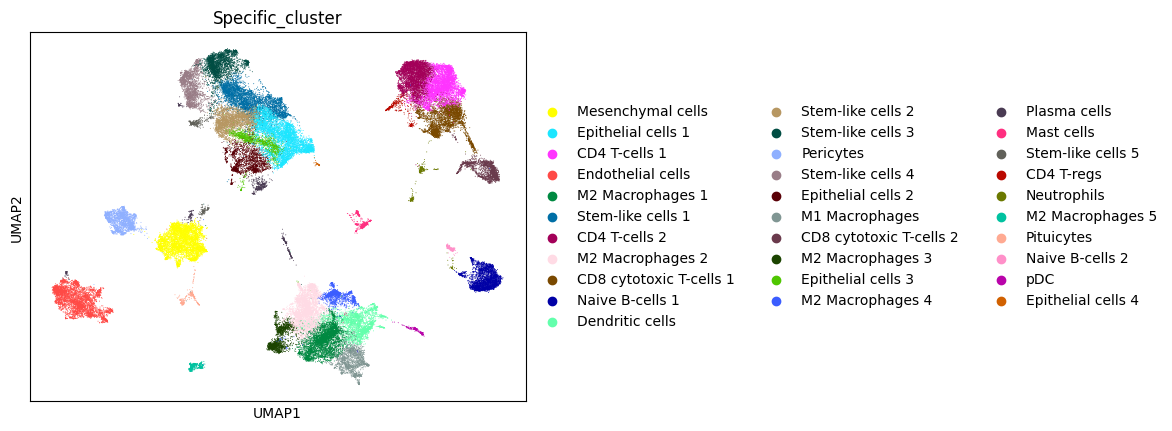

In [ ]:
sc.pl.umap(adata_final, color=["Specific_cluster"])

<ipython-input-8-375ae0fb2423>:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_counts = df.groupby(['batch', 'broad_cluster']).size().unstack(fill_value=0)


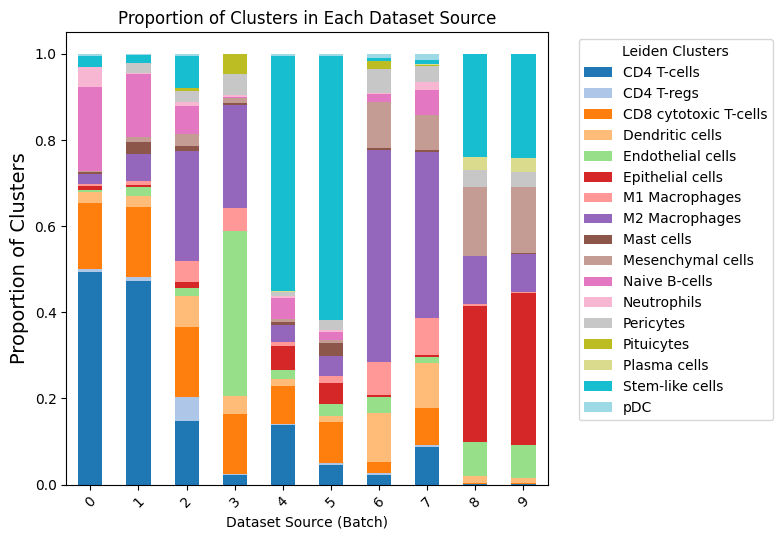

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Extract the relevant columns
df = adata_final.obs[['broad_cluster', 'batch']]
# Calculate counts and normalize
cluster_counts = df.groupby(['batch', 'broad_cluster']).size().unstack(fill_value=0)
cluster_proportions = cluster_counts.div(cluster_counts.sum(axis=1), axis=0)

# Reindex to ensure consistent cluster order
cluster_proportions = cluster_proportions.reindex(sorted(cluster_proportions.columns), axis=1)

# Create the stacked bar plot
cluster_proportions.plot(kind='bar', stacked=True, colormap='tab20', figsize=(8, 5.5))

#rotate x ticks
plt.xticks(rotation=45)
# Add labels and title
plt.xlabel('Dataset Source (Batch)')
plt.ylabel('Proportion of Clusters', fontsize=14)
plt.title('Proportion of Clusters in Each Dataset Source')
plt.legend(title='Leiden Clusters', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Show the plot
plt.show()

#Double checking whether samples 6, 7, 8, 9 are biological replicates or technical


In [ ]:
subset_8_9 = adata_final[adata_final.obs.batch.isin(["6","7","8","9"])]
subset_8_9.obs["0"].value_counts().hist()

In [ ]:
subset_8_9.obs["0"].value_counts().head(200)

In [ ]:
dataset_dict = {
    "0": "OES21644390B",
    "1": "OES21644790B",
    "2": "OES231739100B",
    "3": "OES232243100B",
    "4": "OES232245100B",
    "5": "OES232911100B",
    "6": "SRX28013270",
    "7": "SRX28013271",
    "8": "SRX28013272",
    "9": "SRX28013273",
}

dataset_dict = {str(k): v for k, v in dataset_dict.items()}
adata_final.obs["dataset"] = adata_final.obs["batch"].map(dataset_dict)


patient_dict = {
    "0": "patient_1",
    "1": "patient_2",
    "2": "patient_3",
    "3": "patient_4",
    "4": "patient_5",
    "5": "patient_6",
    "6": "patient_7",
    "7": "patient_7",
    "8": "patient_8",
    "9": "patient_8"}

patient_dict = {str(k): v for k, v in patient_dict.items()}
adata_final.obs["patient"] = adata_final.obs["batch"].map(patient_dict)

# Saving anndata object

In [ ]:
#finally save adata object as it is
adata_final.write(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/finalised_annotated_0402.h5ad")

# Loading it back for quick sanity marker check

In [ ]:
import scanpy as sc
adata_final = sc.read(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/finalised_annotated_0402.h5ad")

# A small set of epithelial cells clustered with "Plasma cells", but they need to be renamed back to epithelial

In [ ]:
import numpy as np
import pandas as pd

genes_of_interest = ["KLF5", "TACSTD2", "CLDN1"]

# Sanity check — make sure all genes exist in the data
missing = [g for g in genes_of_interest if g not in adata_final.var_names]
if missing:
    raise ValueError(f"Genes not found in adata_final.var_names: {missing}")

# Get expression matrix for those genes (cells x genes)
expr = adata_final[:, genes_of_interest].X

# Handle sparse vs dense matrices
if hasattr(expr, "toarray"):
    expr = expr.toarray()

expr_df = pd.DataFrame(
    expr,
    index=adata_final.obs_names,
    columns=genes_of_interest,
)

# Build the reassignment mask
is_plasma = adata_final.obs["broad_cluster"] == "Plasma cells"
expresses_all = (expr_df["KLF5"] > 0) & (expr_df["TACSTD2"] > 0) & (expr_df["CLDN1"] > 0)

mask = is_plasma & expresses_all

# Need to handle the Categorical dtype — add "Epithelial cells" as a valid category first
# (it almost certainly already is, but this guards against the edge case)
if "Epithelial cells" not in adata_final.obs["broad_cluster"].cat.categories:
    adata_final.obs["broad_cluster"] = adata_final.obs["broad_cluster"].cat.add_categories(
        ["Epithelial cells"]
    )

adata_final.obs.loc[mask, "broad_cluster"] = "Epithelial cells"

print(f"Reassigned {mask.sum()} cells from Plasma cells → Epithelial cells")
print(adata_final.obs["broad_cluster"].value_counts())

Reassigned 374 cells from Plasma cells → Epithelial cells
broad_cluster
Stem-like cells          11831
M2 Macrophages           11343
CD4 T-cells               8448
Epithelial cells          8313
Mesenchymal cells         5029
CD8 cytotoxic T-cells     4947
Endothelial cells         4284
Naive B-cells             3176
Dendritic cells           2706
Pericytes                 2149
M1 Macrophages            1778
Mast cells                 610
CD4 T-regs                 468
Neutrophils                461
Pituicytes                 394
Plasma cells               361
pDC                        279
Name: count, dtype: int64


In [ ]:
import scanpy as sc
adata_final.write(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/finalised_annotated_2026_06_17.h5ad")

# Loading back data

In [ ]:
import scanpy as sc
adata_final = sc.read(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/finalised_annotated_2026_06_17.h5ad")

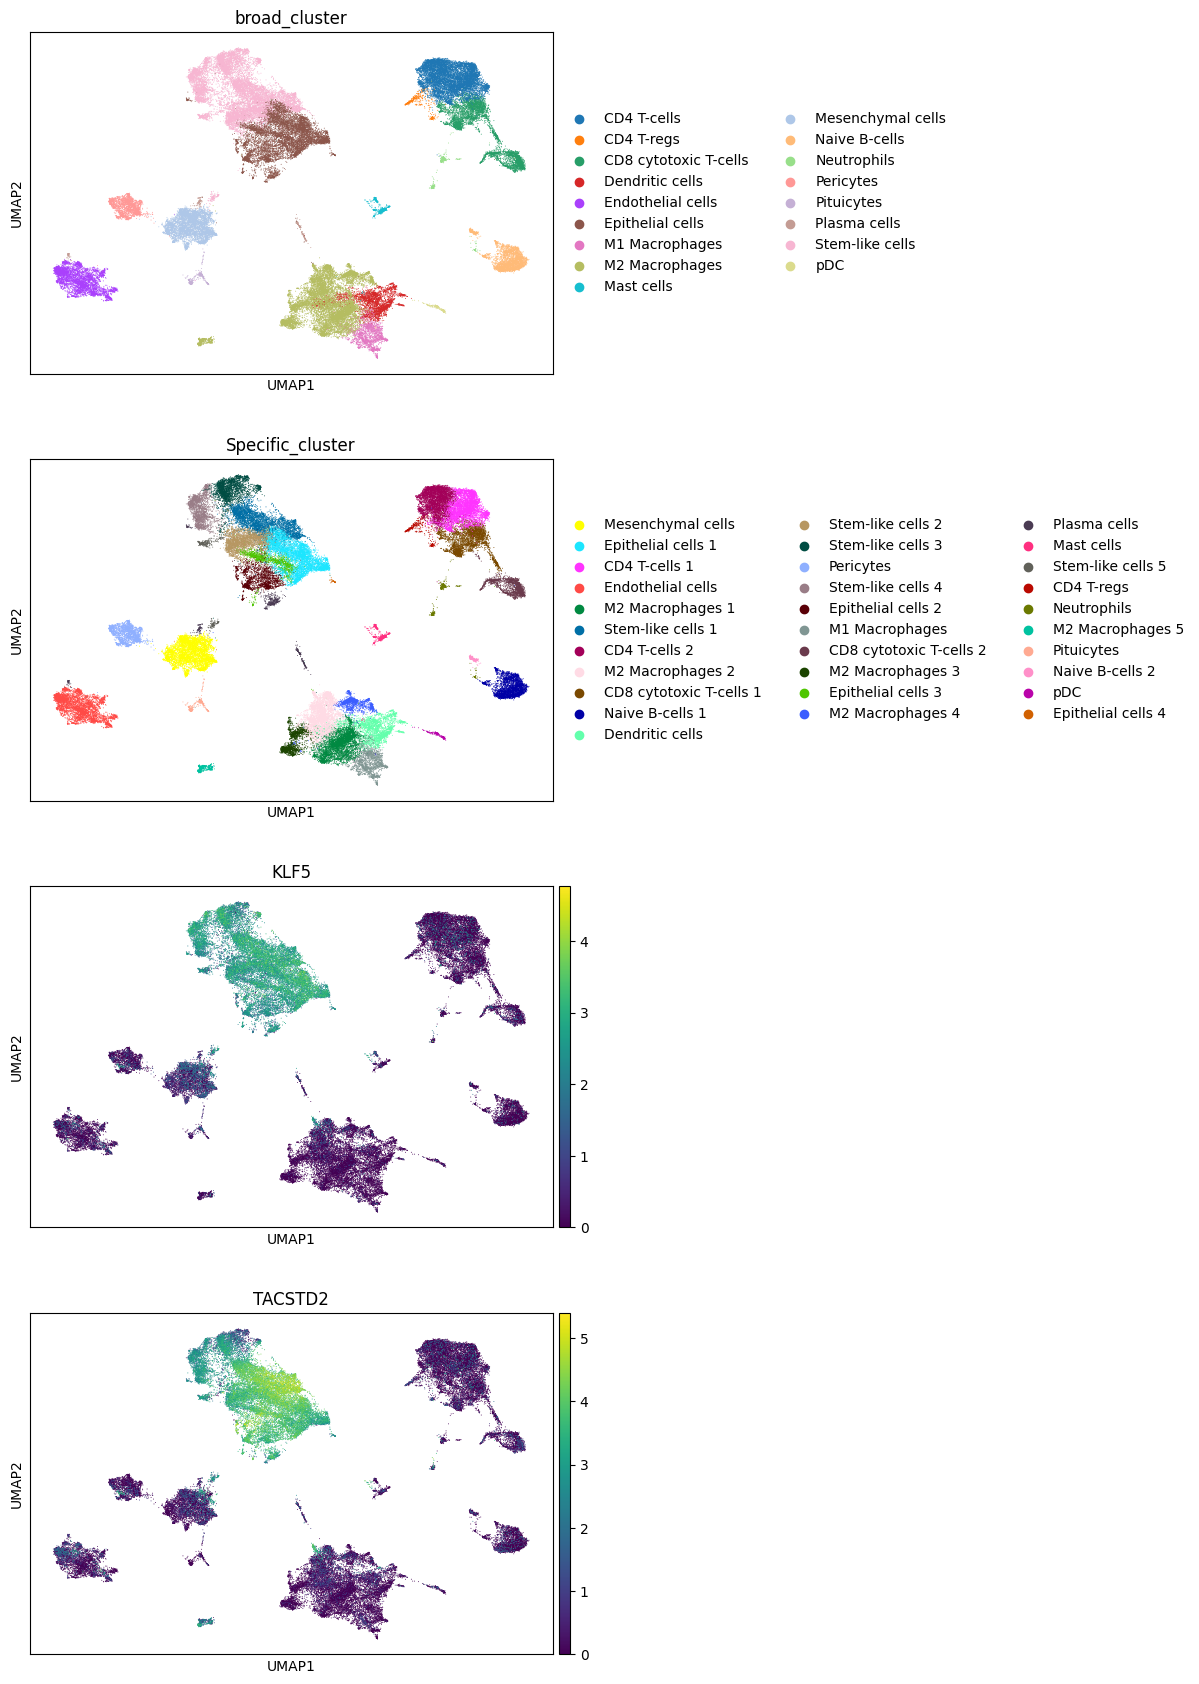

In [ ]:
sc.pl.umap(adata_final, color=["broad_cluster", "Specific_cluster","KLF5","TACSTD2"], ncols=1, use_raw=False)

In [ ]:
adata_final.X[:10,:10].toarray()

array([[0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 1.2679685, 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.     

# Recoloring cell types for the final scheme - Figure 1C

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import scanpy as sc

palette = sns.color_palette("tab20", n_colors=20)

color_mapping = {
    "Stem-like cells": 18,
    "Macrophages": 7,
    "Epithelial cells": 6,
    "T-cells": 0,
    "Mast cells": 10,
    "Endothelial cells": 5,
    "Pericytes": 15,
    "Mesenchymal cells": 11,
    "Dendritic cells": 3,
    "B-cells": 12,
    "Neutrophils": 13,
    "CD8 cytotoxic T-cells": 2,
    "CD4 T-cells": 0,
    "Naive B-cells": 12,
    "M2 Macrophages": 8,
    "M1 Macrophages": 7,
    "CD4 T-regs": 1,
    "pDC": 19,
    "Plasma cells": 17,
    "Pituicytes": 16,
}

colors_dict = {key: mcolors.to_hex(palette[value]) for key, value in color_mapping.items()}

fig, ax = plt.subplots(figsize=(6, 6))

sc.pl.umap(
    adata_final,
    color=["broad_cluster"],
    palette=colors_dict,
    ax=ax,
    show=False,
    legend_loc="right margin",
    frameon=False,
)

# Force the legend into a single column
legend = ax.get_legend()
if legend is not None:
    handles = legend.legend_handles if hasattr(legend, "legend_handles") else legend.legendHandles
    labels = [t.get_text() for t in legend.get_texts()]
    legend.remove()
    ax.legend(
        handles,
        labels,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        frameon=False,
        fontsize=8,
    )

# Make backgrounds transparent
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.savefig(
    "umap_broad_cluster.png",
    dpi=800,
    bbox_inches="tight",
    transparent=True,
    format="png",
)
plt.close()

# Generating feature plots for the paper - Figure 1D

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

sc.pl.umap(
    adata_final,
    color=["SOX2"],
    cmap="Reds",
    ax=ax,
    show=False,
    legend_loc="right margin",
    frameon=False,
    use_raw=False,
)

# Force the legend into a single column
legend = ax.get_legend()
if legend is not None:
    handles = legend.legend_handles if hasattr(legend, "legend_handles") else legend.legendHandles
    labels = [t.get_text() for t in legend.get_texts()]
    legend.remove()
    ax.legend(
        handles,
        labels,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        frameon=False,
        fontsize=8,
    )

# Make backgrounds transparent
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.savefig(
    "sox2.png",
    dpi=800,
    bbox_inches="tight",
    transparent=True,
    format="png",
)
plt.close()

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

sc.pl.umap(
    adata_final,
    color=["MKI67"],
    cmap="Reds",
    ax=ax,
    show=False,
    legend_loc="right margin",
    frameon=False,
    use_raw=False,
)

# Force the legend into a single column
legend = ax.get_legend()
if legend is not None:
    handles = legend.legend_handles if hasattr(legend, "legend_handles") else legend.legendHandles
    labels = [t.get_text() for t in legend.get_texts()]
    legend.remove()
    ax.legend(
        handles,
        labels,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        ncol=1,
        frameon=False,
        fontsize=8,
    )

# Make backgrounds transparent
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.savefig(
    "mki67.png",
    dpi=800,
    bbox_inches="tight",
    transparent=True,
    format="png",
)
plt.close()

# Generating Pseudobulk object for differential expression

In [ ]:
import decoupler as dc


In [ ]:
adata_new = sc.AnnData(adata_final.raw.X)
adata_new.obs = adata_final.obs
adata_new.var = adata_final.raw.var.copy()
adata_new

AnnData object with n_obs × n_vars = 66577 × 27578
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'dataset', 'batch', '_scvi_batch', '_scvi_labels', 'leiden_scVI', '_scvi_raw_norm_scaling', 'broad_cluster', 'Specific_cluster', 'patient'
    var: '0', 'feature_types', 'mt', 'ribo', 'malat', 'n_cells_by_counts-0', 'mean_counts-0', 'log1p_mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_total_counts-0', 'n_cells_by_counts-1', 'mean_counts-1', 'log1p_mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_total_counts-1', 'n_cells_by_counts-2', 'mean_counts-2', 'log1p_mean_counts-2', 'pct_dropo

In [ ]:
adata_new.X[:10,:10].toarray()

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [ ]:
import pandas as pd
import numpy as np

if not hasattr(pd.Series, "nonzero"):
    pd.Series.nonzero = lambda self: np.asarray(self).nonzero()

In [ ]:


pdata = dc.get_pseudobulk(
        adata_new,
        sample_col='patient',
        groups_col='broad_cluster',
        mode='sum',
        min_cells=35,
        min_counts=0
    )

In [ ]:
pdata.obs["broad_cluster"].value_counts()

,count
broad_cluster,
CD8 cytotoxic T-cells,8
Dendritic cells,8
M2 Macrophages,8
CD4 T-cells,7
Pericytes,7
Endothelial cells,7
M1 Macrophages,7
Stem-like cells,7
Epithelial cells,6


In [ ]:
#find total counts of Tacstd2
adata_final.raw.X[:,adata_final.raw.var_names=="TACSTD2"].sum()

657151.0

In [ ]:
##find total counts of Tacstd2 in pdata
pdata.X[:,pdata.var_names=="TACSTD2"].sum()

656196.0

In [ ]:
pdata.obs.columns = pdata.obs.columns.astype(str)
pdata.var.columns = pdata.var.columns.astype(str)
for col in pdata.obs.columns:
  pdata.obs[col] = pdata.obs[col].astype(str)
pdata.write(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/pseudobulk_data_2026_06_17.h5ad")

# Dotplot for publication - Figure 1B

In [ ]:
import pandas as pd
cell_type_order = [
    "Stem-like cells",
    "Epithelial cells",
    "Pituicytes",
    "Mesenchymal cells",
    "Endothelial cells",
    "Pericytes",
    "Neutrophils",
    "Dendritic cells",
    "pDC",
    "M1 Macrophages",
    "M2 Macrophages",
    "CD4 T-cells",
    "CD4 T-regs",
    "CD8 cytotoxic T-cells",
    "Naive B-cells",
    "Plasma cells",
    "Mast cells",

]

# Set the categorical order on the annotation column itself
adata_final.obs["broad_cluster"] = pd.Categorical(
    adata_final.obs["broad_cluster"],
    categories=cell_type_order,
    ordered=True,
)

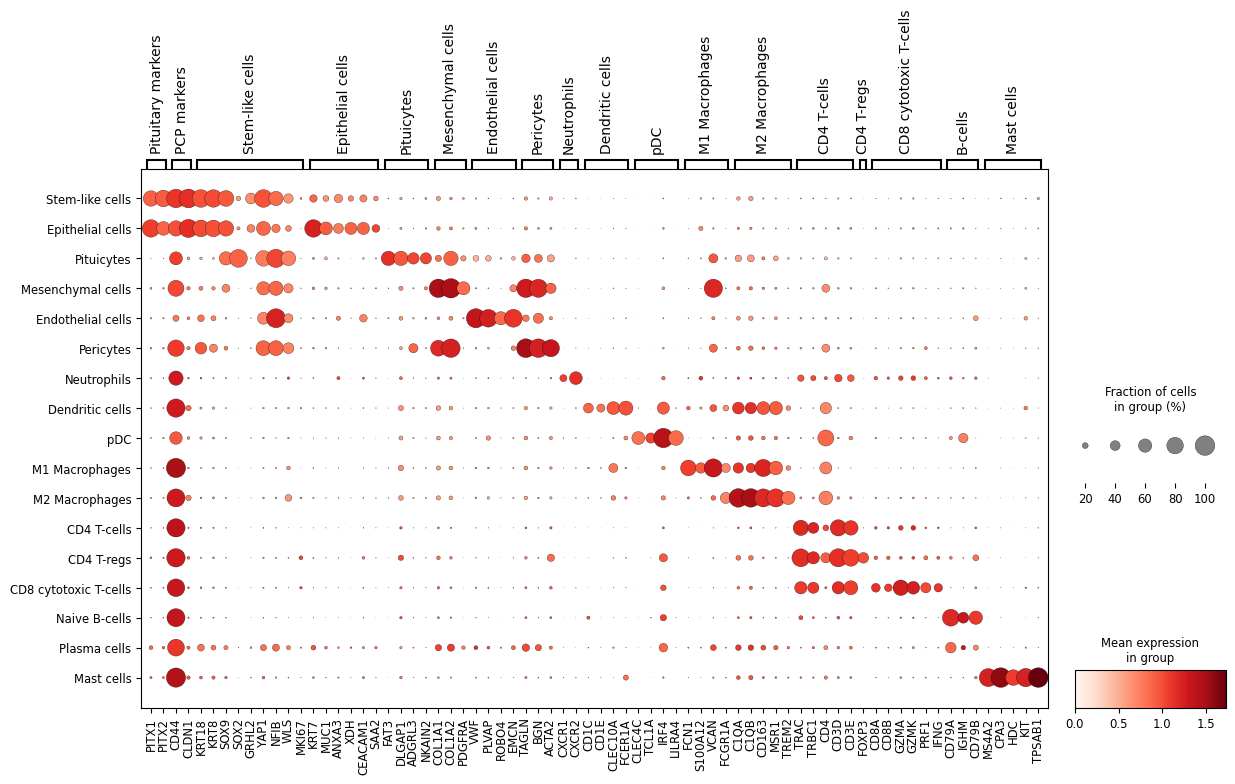

<Figure size 640x480 with 0 Axes>

In [ ]:


# Define markers dictionary with curated markers for each cell type
markers = {
    "Pituitary markers" : ["PITX1","PITX2"],
    "PCP markers": ["CD44","CLDN1"],
    "Stem-like cells": ["KRT18","KRT8", "SOX9", "SOX2", "GRHL2","YAP1","NFIB","WLS","MKI67"],
    "Epithelial cells": ["KRT7","MUC1","ANXA3","XDH","CEACAM1","SAA2"],
    "Pituicytes": ["FAT3", "DLGAP1", "ADGRL3", "NKAIN2"],
    "Mesenchymal cells": ["COL1A1", "COL1A2", "PDGFRA"],
    "Endothelial cells": ["VWF", "PLVAP", "ROBO4", "EMCN"],
    "Pericytes": ["TAGLN", "BGN","ACTA2"],
    "Neutrophils": ["CXCR1", "CXCR2","CSFJR"],
    "Dendritic cells": ["CD1C", "CD1E", "CLEC10A", "FCER1A"],
    "pDC": ["CLEC4C", "TCL1A", "IRF4", "LILRA4"],
    "M1 Macrophages": ['FCN1', 'S100A12', 'VCAN', 'FCGR1A'],
    "M2 Macrophages": ["C1QA", "C1QB", "CD163", "MSR1", "TREM2"],
    "CD4 T-cells" : ["TRAC","TRBC1","CD4","CD3D", "CD3E",],
    "CD4 T-regs": ["FOXP3"],
    "CD8 cytotoxic T-cells": ["CD8A", "CD8B","GZMA", "GZMK", "PRF1", "IFNG"],
    "B-cells": [ "CD79A", "IGHM","CD79B"],
    "Mast cells": ["MS4A2", "CPA3", "HDC","KIT", "TPSAB1"]
}


# Remove values from each list that are not in var
markers = {k: [x for x in v if x in adata_final.var_names] for k, v in markers.items()}

# Create the dotplot
sc.pl.dotplot(adata_final,
              markers,
              groupby="broad_cluster",
              figsize=(14, 7),
              use_raw=False,
              log=True,
              mean_only_expressed=True)

plt.tight_layout()

In [ ]:
markers = {
    "Pituitary markers" : ["PITX1","PITX2"],
    "PCP markers": ["CD44","CLDN1"],
    "Stem-like cells": ["KRT18","KRT8", "SOX9", "SOX2", "GRHL2","YAP1","NFIB","WLS","MKI67"],
    "Epithelial cells": ["KRT7","MUC1","ANXA3","XDH","CEACAM1","SAA2"],
    "Pituicytes": ["FAT3", "DLGAP1",],
    "Mesenchymal cells": [ "COL1A2", "PDGFRA"],
    "Endothelial cells": ["ROBO4", "EMCN"],
    "Pericytes": ["ACTA2"],
    "Neutrophils": ["CXCR1", "CXCR2"],
    "Dendritic cells": ["CD1C", "CD1E"],
    "pDC": ["CLEC4C", "TCL1A"],
    "M1 Macrophages": ['FCN1', 'S100A12',],
    "M2 Macrophages": ["C1QA", "C1QB", ],
    "CD4 T-cells" : ["TRAC","CD4",],
    "CD4 T-regs": ["CD3D","FOXP3"],
    "CD8 cytotoxic T-cells": ["CD8A", "GZMA"],
    "B-cells": [ "CD79A", "IGHM"],
    "Plasma cells": ["MZB1","JCHAIN"],
    "Mast cells": ["MS4A2", "CPA3"]

}


# Remove values from each list that are not in var
markers = {k: [x for x in v if x in adata_final.var_names] for k, v in markers.items()}

import matplotlib.pyplot as plt
import scanpy as sc

sc.pl.dotplot(
    adata_final,
    markers,
    groupby="broad_cluster",
    figsize=(11, 4.5),
    use_raw=False,
    log=True,
    mean_only_expressed=False,
    show=False,
)

plt.savefig(
    "dotplot_broad_cluster.svg",
    dpi=800,
    bbox_inches="tight",
    transparent=True,
    format="svg",
)
plt.close()

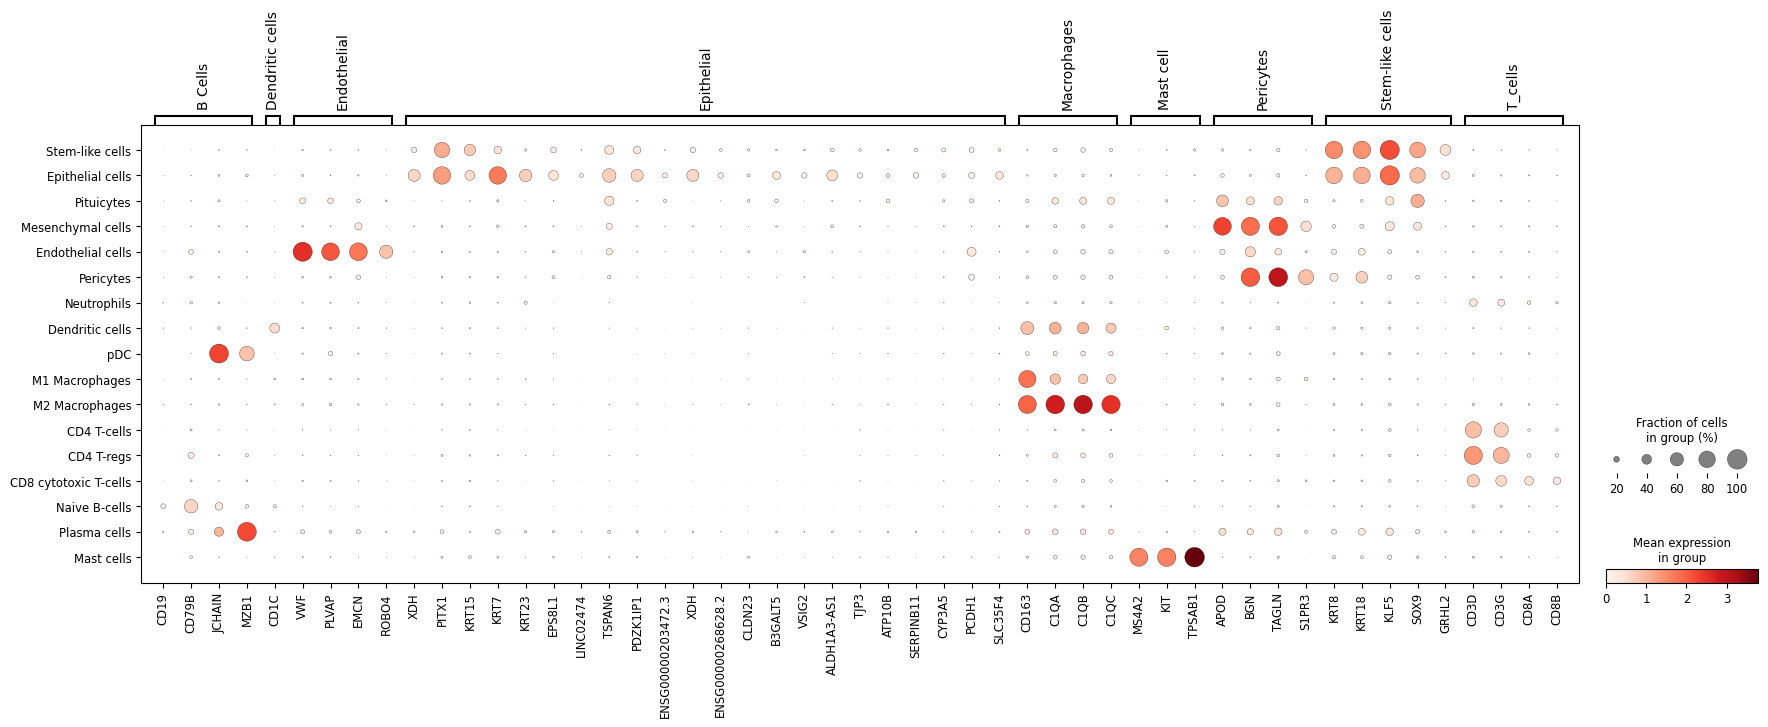

In [ ]:
marker_genes_dict = {
    "B Cells": ["CD19", "CD79B","JCHAIN", "MZB1"],
    "Dendritic cells": ["CD1C"],
    "Endothelial": ["VWF","PLVAP","EMCN","ROBO4"],
    "Epithelial": ["XDH","PITX1","KRT15", "KRT7","KRT23",
                   'EPS8L1',
 'LINC02474',
 'TSPAN6',
 'PDZK1IP1',
 'ELF3-AS1',
 'ENSG00000203472.3',
 'XDH',
 'ENSG00000268628.2',
 'CLDN23',
 'B3GALT5',
 'SORD',
 'VSIG2',
 'ALDH1A3-AS1',
 'TJP3',
 'ATP10B',
 'SERPINB11',
 'ENSG00000289396.1',
 'CYP3A5',
 'PCDH1',
 'SLC35F4',
],
    "Macrophages": ["CD163", "C1QA", "C1QB", "C1QC"],
    "Mast cell" : ["MS4A2","KIT", "TPSAB1"],
    "Pericytes": ["APOD","BGN","TAGLN","S1PR3","COL1A3"],
    "Stem-like cells": ["KRT8","KRT18", "KLF5", "SOX9", "GRHL2"],
    "T_cells": ["CD3D","CD3G","CD8A","CD8B"],

}


#only keep those in adata.var_names
marker_genes_dict = {key: [gene for gene in value if gene in adata_final.var_names] for key, value in marker_genes_dict.items()}
sc.pl.dotplot(adata_final, marker_genes_dict, groupby="broad_cluster", log=True)

# Additional dotplots for the paper, using stem - immune interactions - Figure 3A


In [ ]:
adata_new = sc.AnnData(adata_final.raw.X)
adata_new.obs = adata_final.obs
adata_new.var = adata_final.raw.var.copy()

In [ ]:
adata_new.X[:10,:10].toarray()

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [ ]:
import pandas as pd
cell_type_order = [
    "Stem-like cells",
    "Epithelial cells",
    "Pituicytes",
    "Mesenchymal cells",
    "Endothelial cells",
    "Pericytes",
    "Neutrophils",
    "Dendritic cells",
    "pDC",
    "M1 Macrophages",
    "M2 Macrophages",
    "CD4 T-cells",
    "CD4 T-regs",
    "CD8 cytotoxic T-cells",
    "Naive B-cells",
    "Plasma cells",
    "Mast cells",

]

# Set the categorical order on the annotation column itself
adata_new .obs["broad_cluster"] = pd.Categorical(
    adata_new .obs["broad_cluster"],
    categories=cell_type_order,
    ordered=True,
)

In [ ]:
"CD47" in adata_new.var_names

True

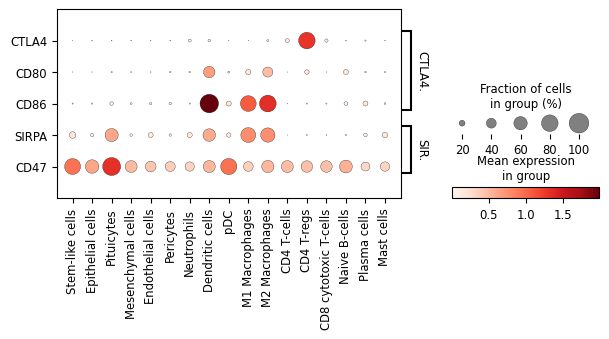

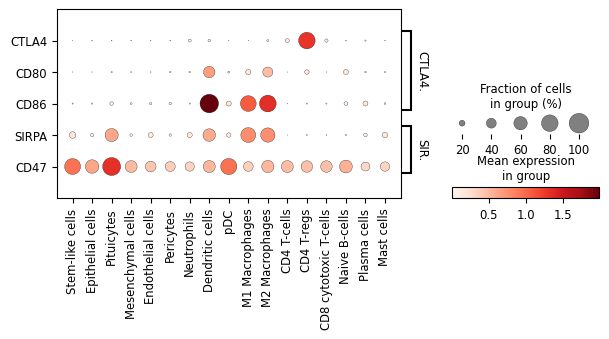

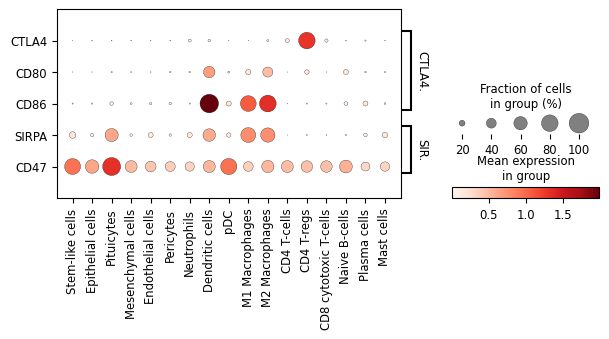

In [ ]:
import matplotlib.pyplot as plt

marker_genes_dict = {
    "CTLA4-CD80/CD86": ["CTLA4", "CD80", "CD86"],
    "SIRPA-CD47": ["SIRPA", "CD47"]
}
marker_genes_dict = {key: [gene for gene in value if gene in adata_new .var_names]
                     for key, value in marker_genes_dict.items()}

dp = sc.pl.dotplot(
    adata_new,
    marker_genes_dict,
    groupby="broad_cluster",
    log=True,
    swap_axes=True,
    figsize=(7,2),
    return_fig=True
)
dp.make_figure()         # builds the figure

dp.savefig("dotplot1.png", dpi=800, bbox_inches="tight")
dp.savefig("dotplot1.svg", bbox_inches="tight")

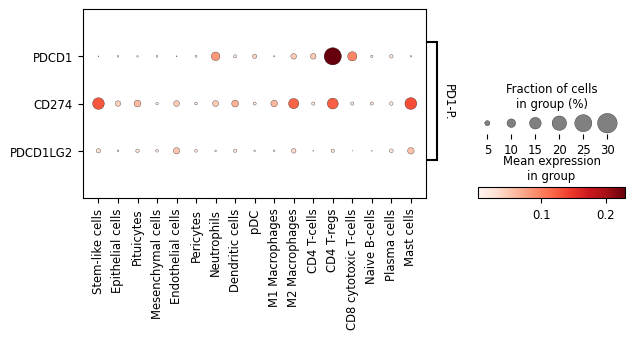

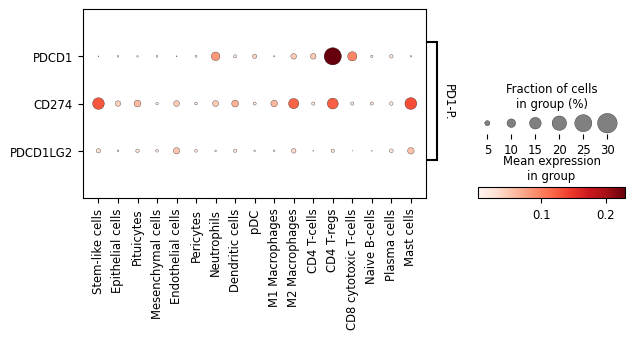

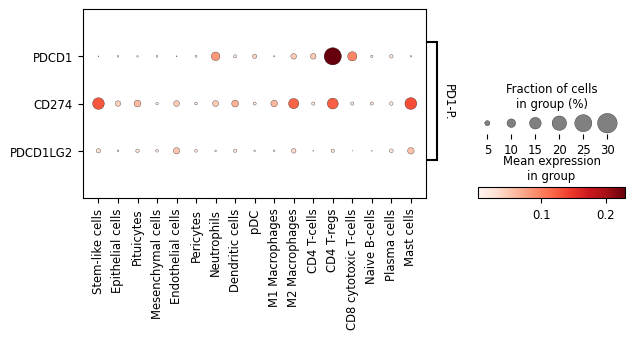

In [ ]:
import matplotlib.pyplot as plt

marker_genes_dict = {
    "PD1-PD-L1/PD-L2": ["PDCD1", "CD274", "PDCD1LG2"]
}
# only keep those in adata.var_names
marker_genes_dict = {key: [gene for gene in value if gene in adata_new .var_names]
                     for key, value in marker_genes_dict.items()}

dp = sc.pl.dotplot(
    adata_new ,
    marker_genes_dict,
    groupby="broad_cluster",
    log=True,
    swap_axes=True,
    figsize=(7, 2),
    return_fig=True,      # <-- this returns the DotPlot object
)
dp.make_figure()         # builds the figure

dp.savefig("dotplot2.png", dpi=800, bbox_inches="tight")
dp.savefig("dotplot2.svg", bbox_inches="tight")

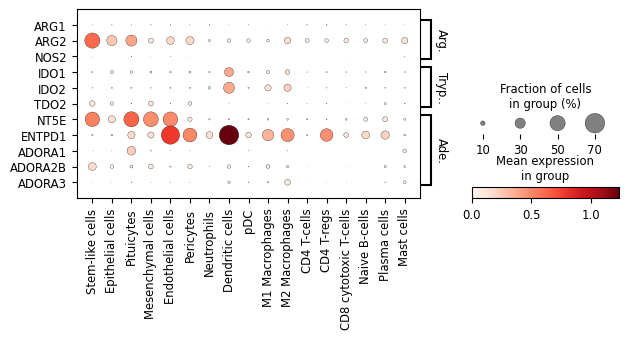

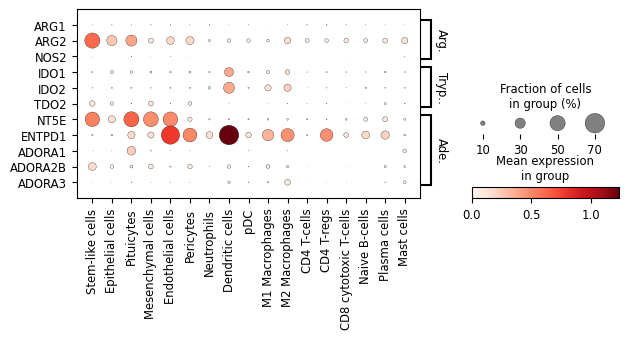

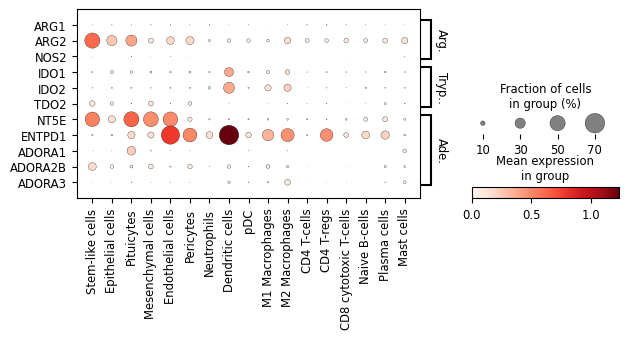

In [ ]:
import matplotlib.pyplot as plt

marker_genes_dict = {
    "Arg.": ["ARG1", "ARG2", "NOS2"],
    "Tryp.\n/IDO": ["IDO1", "IDO2", "TDO2"],
    "Ade.": ["NT5E", "ENTPD1", "ADORA1","ADORA2A","ADORA2B","ADORA3"],

}

# only keep those in adata.var_names
marker_genes_dict = {key: [gene for gene in value if gene in adata_new.var_names]
                     for key, value in marker_genes_dict.items()}

dp = sc.pl.dotplot(
    adata_new ,
    marker_genes_dict,
    groupby="broad_cluster",
    log=True,
    swap_axes=True,
    figsize=(7, 2),
    return_fig=True,      #
)
dp.make_figure()         #

dp.savefig("dotplot3.png", dpi=800, bbox_inches="tight")
dp.savefig("dotplot3.svg", bbox_inches="tight")

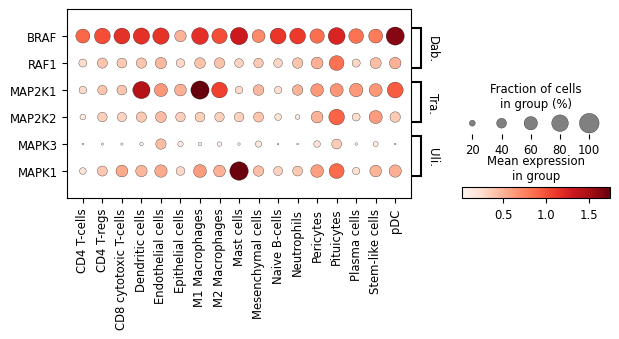

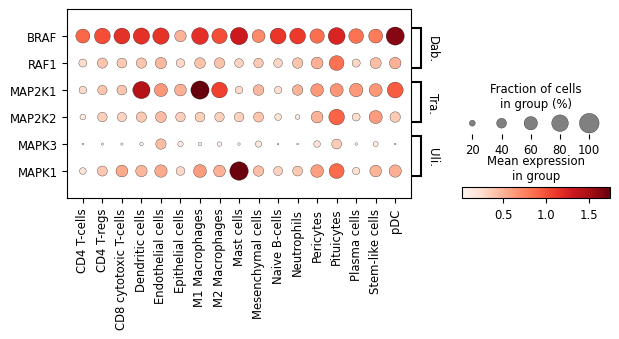

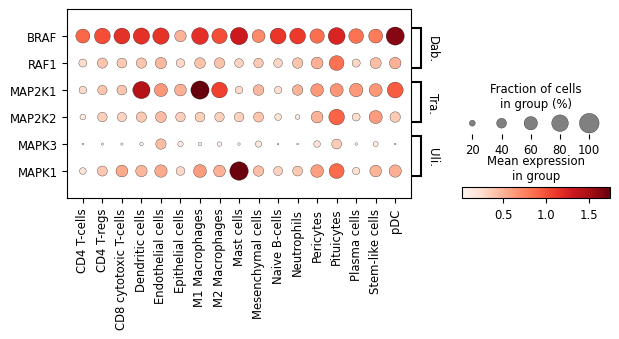

In [ ]:
import matplotlib.pyplot as plt

marker_genes_dict = {
    "Dabrafenib": ["BRAF", "RAF1"],
    "Trametinib": ["MAP2K1", "MAP2K2"],
    "Ulixertinib": ["MAPK3", "MAPK1"],
}

# only keep those in adata.var_names
marker_genes_dict = {key: [gene for gene in value if gene in adata_new.var_names]
                     for key, value in marker_genes_dict.items()}

dp = sc.pl.dotplot(
    adata_new ,
    marker_genes_dict,
    groupby="broad_cluster",
    log=True,
    swap_axes=True,
    figsize=(7, 2),
    return_fig=True,      #
)
dp.make_figure()         #

dp.savefig("dotplot_dab_tra_uli.png", dpi=800, bbox_inches="tight")
dp.savefig("dotplot_dab_tra_uli.svg", bbox_inches="tight")

In [ ]:
#print all used package versions
!pip freeze > versions.txt
!cat versions.txt

absl-py==1.4.0
accelerate==1.5.2
aiobotocore==2.21.1
aiohappyeyeballs==2.6.1
aiohttp==3.11.14
aiohttp-retry==2.9.1
aioitertools==0.12.0
aiosignal==1.3.2
alabaster==1.0.0
albucore==0.0.23
albumentations==2.0.5
ale-py==0.10.2
altair==5.5.0
amqp==5.3.1
anndata==0.11.4
annotated-types==0.7.0
annoy==1.17.3
antlr4-python3-runtime==4.9.3
anyio==4.9.0
appdirs==1.4.4
argon2-cffi==23.1.0
argon2-cffi-bindings==21.2.0
array_api_compat==1.11.2
array_record==0.7.1
arrow==1.3.0
arviz==0.21.0
asciitree==0.3.3
astropy==7.0.1
astropy-iers-data==0.2025.3.17.0.34.53
astunparse==1.6.3
async-lru==2.0.5
asyncssh==2.20.0
atpublic==5.1
attrs==25.3.0
audioread==3.0.1
autograd==1.7.0
babel==2.17.0
backcall==0.2.0
beautifulsoup4==4.13.3
betterproto==2.0.0b6
bigframes==1.41.0
bigquery-magics==0.8.0
billiard==4.2.1
biopython==1.85
biothings_client==0.4.1
bleach==6.2.0
blinker==1.9.0
blis==1.2.0
blosc2==3.2.0
bokeh==3.6.3
boto3==1.37.1
botocore==1.37.1
Bottleneck==1.4.2
bqplot==0.12.44
branca==0.8.1
CacheControl==0.